# results.ipynb — 2-ME/DMI: barcha hisoblash natijalari

PbI₂, PbBr₂, FAI va MABr prekursorlarining 2-ME/DMI aralashmasida erishi. **Bitta `Run All`** barcha rasm, jadval, yakuniy sonlar (6-bo'lim) va `results.zip` (7-bo'lim) ni hosil qiladi.

Bu notebook `Nazariy_hisoblashlar_2ME_DMI.docx` dagi har bir qadam natijasini ORCA chiqish fayllaridan hosil qiladi.
Notebookning bo'limlari docx bo'limlari bilan bir xil tartibda.

| docx | Notebook natijasi |
| --- | --- |
| Hisoblash tafsilotlari, tenglama (1) | energiyalar jadvali, mavhum chastota va tugallanish tekshiruvi |
| Solvat klaster modellari | **Jadval 1**, **Rasm 1**, **Rasm S2** |
| Termodinamik model, (2)–(4) | ΔG_b va β_b jadvali, **Rasm 2** |
| Termodinamik model, (5)–(6) | S_sat(φ) va c_b(φ), **Rasm 4** |
| Eruvchanlik chegarasi, (7) | φ* jadvali, **Rasm 3**, **Rasm 5**, **Rasm S1** |
| Sezgirlik testlari (taqrizchilarga javob) | **Jadval S1**, **Jadval S2**, **Jadval S3**, **Rasm S3** |
| Hisoblangan IR siljishlari (R2-3) | **Jadval S4**, `tables/ir_bands.csv` (5b-bo'lim) |
| Matndagi barcha sonlar | `tables/summary_numbers.txt` (6-bo'lim) |
| Yuborish uchun | `results.zip` (7-bo'lim) |

Grafiklardagi barcha matn ingliz tilida, Times New Roman, bold. Rasmlar `figures/` ga (PDF + 600 dpi PNG), jadvallar `tables/` ga (CSV) yoziladi.

**Papka tuzilishi** (ROOT = notebook turgan `2ME-DMI` papkasi):
```
2ME-DMI/
├── 2ME/  DMI/            erkin ligandlar (ixtiyoriy, boshqa joyda ham bo'lishi mumkin)
├── PbI2/  PbBr2/  FAI/  MABr/
│     └── calc/<nom>/<nom>_s2_r2scan.out, _s2_r2scan.xyz, _s3_freq.out
│                       (+ _s4_r2freq.out, _s5_cpcm2me.out, _s5_cpcmdmi.out, _s6_wb97mv.out — 5-bo'lim)
├── ligands_alpb/2ME, DMI  ion juftlari seriyasi uchun ALPB(metanol) dagi erkin erituvchilar
└── solubility_paper.ipynb
```
Natijalar avtomatik topiladi (2-katak). Topilgan yo'llar jadvalda ko'rsatiladi; kerak bo'lsa `data` ni qo'lda o'zgartirish mumkin.

## 0. Kiritish

In [1]:
import os, re, glob
from math import comb
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, brentq

# Notebook turgan papka: VS Code (__vsc_ipynb_file__) yoki Jupyter (joriy papka)
_nbfile = globals().get("__vsc_ipynb_file__")
NBDIR = os.path.dirname(os.path.abspath(_nbfile)) if _nbfile else os.getcwd()
# ROOT: ORCA natijalari turgan 2ME-DMI papkasi — notebook papkasi, keyin to'liq yo'l
_cands = [NBDIR, os.getcwd(),
          "/media/doston/72f1eff3-bf18-4476-8539-c8566520c822/FACsPbI3_VASP/FACsPbI3/ORCA/2ME-DMI"]
ROOT = next((c for c in _cands if os.path.isdir(os.path.join(c, "PbI2"))), _cands[-1])
PRECURSORS = ["PbI2", "PbBr2", "FAI", "MABr"]

# koordinatsiya soni n (docx: Solvat klaster modellari)
N_SITES = {"PbI2": 4, "PbBr2": 4, "FAI": 4, "MABr": 4}

# statistik vaznlar g (tenglama 4); berilmagan label uchun g = 1
_ION = {f"b{c+a}_c{c}a{a}": comb(2, c) * comb(2, a) for c in range(3) for a in range(3)}
WEIGHTS = {
    "PbI2":  {"b0": 1, "b1": 4, "b2_cis": 4, "b2_trans": 2, "b3": 4, "b4": 1},
    "PbBr2": {"b0": 1, "b1": 4, "b2_cis": 4, "b2_trans": 2, "b3": 4, "b4": 1},
    "FAI": _ION, "MABr": _ION,
}

# Kalibrlash (docx: Eruvchanlik chegarasi va kalibrlash):
# prekursor -> (toza erituvchi "2ME" yoki "DMI", eksperimental eruvchanlik mol/L); None -> hali o'lchanmagan
CALIB = {"PbI2": ("DMI", None), "PbBr2": ("DMI", None), "FAI": ("2ME", None), "MABr": ("2ME", None)}

# maqsad konsentratsiya c_target, mol/L (tenglama 7)
C_TARGET = {"PbI2": 1.2, "PbBr2": 0.2, "FAI": 1.2, "MABr": 0.2}

DG_ERR = 4.0          # ΔG_b noaniqligi, kJ/mol har bir DMI uchun (asosi: Jadval S2, S3)
S_REF_TEST = [0.1, 0.5, 1.0]   # mol/L, Rasm S3 (R1-2)
T = 298.15

# Rasm 1 panellari: (prekursor, label, sarlavha)
FIG1_PANELS = [
    ("PbI2", "b0", r"PbI$_2$(2ME)$_4$"),       ("PbI2", "b4", r"PbI$_2$(DMI)$_4$"),
    ("PbBr2", "b0", r"PbBr$_2$(2ME)$_4$"),     ("PbBr2", "b4", r"PbBr$_2$(DMI)$_4$"),
    ("FAI", "b0_c0a0", r"FAI(2ME)$_4$"),       ("FAI", "b4_c2a2", r"FAI(DMI)$_4$"),
    ("MABr", "b0_c0a0", r"MABr(2ME)$_4$"),     ("MABr", "b4_c2a2", r"MABr(DMI)$_4$"),
]
FIG1_ROTATION = "-70x,20y,0z"

# Rasm S1 (sezgirlik): nom -> (asosiy prekursor, n, papka). Nom legendada chiqadi (inglizcha).
# Papka ichidagi <nom>_b*_s2_r2scan.out lar avtomatik topiladi.
VARIANTS = {
    # "PbI2, n = 3":            ("PbI2", 3, f"{ROOT}/PbI2_n3"),
    # "PbI2, $\\varepsilon$ = 37.6": ("PbI2", 4, f"{ROOT}/PbI2_eps"),
}

FIGDIR, TABDIR = os.path.join(ROOT, "figures"), os.path.join(ROOT, "tables")
os.makedirs(FIGDIR, exist_ok=True); os.makedirs(TABDIR, exist_ok=True)
print("Notebook papkasi:", NBDIR)
print("ORCA natijalari (ROOT):", ROOT)
print("Rasmlar:", FIGDIR)
print("Jadvallar:", TABDIR)
HA = 2625.4996                    # Eh -> kJ/mol
RT = 8.314462618e-3 * T           # kJ/mol

Notebook papkasi: /media/doston/72f1eff3-bf18-4476-8539-c8566520c822/FACsPbI3_VASP/FACsPbI3/ORCA/2ME-DMI
ORCA natijalari (ROOT): /media/doston/72f1eff3-bf18-4476-8539-c8566520c822/FACsPbI3_VASP/FACsPbI3/ORCA/2ME-DMI
Rasmlar: /media/doston/72f1eff3-bf18-4476-8539-c8566520c822/FACsPbI3_VASP/FACsPbI3/ORCA/2ME-DMI/figures
Jadvallar: /media/doston/72f1eff3-bf18-4476-8539-c8566520c822/FACsPbI3_VASP/FACsPbI3/ORCA/2ME-DMI/tables


### Natijalarni avtomatik topish
Har bir prekursor papkasida `<prekursor>_b*_s2_r2scan.out` fayllari qidiriladi. xTB muhiti (gaz yoki ALPB) `_s3_freq` faylidan aniqlanadi.
Erkin 2ME va DMI uchun prekursor seriyasi bilan **bir xil xTB muhitida** hisoblangan nusxa tanlanadi (tenglama 3 dagi termal tuzatmalar mos bo'lishi uchun).

In [2]:
def files_of(path):
    pick = lambda pat: (sorted(glob.glob(os.path.join(path, pat))) or [None])[0]
    return pick("*_s2_r2scan.out"), pick("*_s3_freq.out"), pick("*_s2_r2scan.xyz")


def xtb_env(path):
    f3 = files_of(path)[1]
    if not f3:
        return "?"
    txt = open(f3, errors="ignore").read(20000)
    m = re.search(r"ALPB\(([^)]+)\)", txt)
    return f"ALPB({m.group(1)})" if m else "gas"


def discover(pre_dir, prefix):
    """<prefix>_<label>_s2_r2scan.out -> {label: papka}"""
    out = {}
    for f in sorted(glob.glob(os.path.join(pre_dir, "**", f"{prefix}_*_s2_r2scan.out"), recursive=True)):
        lab = os.path.basename(f)[len(prefix) + 1:-len("_s2_r2scan.out")]
        if re.match(r"b\d", lab) and lab not in out:
            out[lab] = os.path.dirname(f)
    return out


def find_ligand(name, env, prefer):
    """name_s2_r2scan.out ni avval prefer papkada, keyin ROOT/name va butun ROOT da qidiradi"""
    cands = []
    for base in [prefer, os.path.join(ROOT, name), ROOT]:
        cands += [os.path.dirname(f) for f in
                  glob.glob(os.path.join(base, "**", f"{name}_s2_r2scan.out"), recursive=True)]
    seen = []
    for c in cands:
        if c not in seen:
            seen.append(c)
    same = [c for c in seen if xtb_env(c) == env]
    return (same or seen or [None])[0], bool(same)


data, LIG, rows = {}, {}, []
for pre in PRECURSORS:
    sp = discover(os.path.join(ROOT, pre), pre)
    if not sp:
        print(f"{pre}: natija topilmadi ({ROOT}/{pre})")
        continue
    data[pre] = sp
    env = xtb_env(next(iter(sp.values())))
    LIG[pre] = {}
    for lig in ("2ME", "DMI"):
        p, ok = find_ligand(lig, env, os.path.join(ROOT, pre))
        LIG[pre][lig] = p
        if p is None:
            print(f"OGOHLANTIRISH: {pre} uchun erkin {lig} topilmadi")
        elif not ok:
            print(f"OGOHLANTIRISH: {pre} seriyasi {env} da, lekin {lig} faqat {xtb_env(p)} da hisoblangan")
        rows.append(dict(prekursor=pre, tur=f"erkin {lig}", xTB=xtb_env(p) if p else "—",
                         papka=os.path.relpath(p, ROOT) if p else "—"))
    for lab, p in sp.items():
        rows.append(dict(prekursor=pre, tur=lab, xTB=xtb_env(p), papka=os.path.relpath(p, ROOT)))
found = pd.DataFrame(rows)
display(found)
from matplotlib import font_manager
_have = {f.name for f in font_manager.fontManager.ttflist}
SERIF = next((f for f in ["Times New Roman", "Liberation Serif", "Nimbus Roman", "DejaVu Serif"]
              if f in _have))
if SERIF != "Times New Roman":
    print(f"Times New Roman topilmadi, {SERIF} ishlatiladi "
          "(o'rnatish: sudo apt install ttf-mscorefonts-installer && rm -rf ~/.cache/matplotlib)")

mpl.rcParams.update({
    # Times New Roman, hamma matn bold
    "font.family": "serif", "font.serif": [SERIF], "font.weight": "bold",
    "axes.labelweight": "bold", "axes.titleweight": "bold",
    "mathtext.fontset": "custom", "mathtext.rm": f"{SERIF}:bold",
    "mathtext.it": f"{SERIF}:bold:italic", "mathtext.bf": f"{SERIF}:bold",
    "mathtext.default": "bf", "mathtext.cal": f"{SERIF}:bold", "mathtext.sf": f"{SERIF}:bold",
    "font.size": 9, "axes.labelsize": 9, "axes.titlesize": 9, "legend.fontsize": 8,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.linewidth": 1.0,
    "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True, "ytick.right": True,
    "xtick.major.width": 1.0, "ytick.major.width": 1.0, "xtick.minor.width": 0.7,
    "ytick.minor.width": 0.7, "lines.linewidth": 1.4,
    "legend.frameon": False, "savefig.bbox": "tight", "pdf.fonttype": 42, "ps.fonttype": 42,
})
W2 = 7.0                         # ikki ustunli rasm kengligi, dyuym
PRE_TEX = {"PbI2": r"PbI$_2$", "PbBr2": r"PbBr$_2$", "FAI": "FAI", "MABr": "MABr"}
COLORS = ["#1f4e79", "#2e86c1", "#48c9b0", "#f4d03f", "#e67e22", "#c0392b"]


def panel_label(ax, i, x=-0.16, y=1.04):
    ax.text(x, y, f"({'abcdefgh'[i]})", transform=ax.transAxes, fontweight="bold",
            fontsize=9, va="bottom")


def ratio_axis(ax):
    top = ax.secondary_xaxis("top", functions=(lambda x: x, lambda x: x))
    r = [9, 4, 2, 1, 0.5, 0.25]
    top.set_xticks([100 / (1 + v) for v in r])
    top.set_xticklabels(["9:1", "4:1", "2:1", "1:1", "1:2", "1:4"])
    top.set_xlabel("2-ME : DMI (v/v)", labelpad=3)
    top.tick_params(direction="in")
    for t in top.get_xticklabels(): t.set_fontweight("bold")


def save(fig, name):
    os.makedirs(FIGDIR, exist_ok=True)
    for ext, kw in (("pdf", {}), ("png", {"dpi": 600})):
        fig.savefig(os.path.join(FIGDIR, f"{name}.{ext}"), **kw)
    print(f"saqlandi: {os.path.join(FIGDIR, name)}.pdf / .png")

,prekursor,tur,xTB,papka
0,PbI2,erkin 2ME,gas,2ME
1,PbI2,erkin DMI,gas,DMI
2,PbI2,b0,gas,PbI2/calc/PbI2_b0
3,PbI2,b1,gas,PbI2/calc/PbI2_b1
4,PbI2,b2_cis,gas,PbI2/calc/PbI2_b2_cis
5,PbI2,b2_trans,gas,PbI2/calc/PbI2_b2_trans
6,PbI2,b3,gas,PbI2/calc/PbI2_b3
7,PbI2,b4,gas,PbI2/calc/PbI2_b4
8,PbBr2,erkin 2ME,gas,2ME
9,PbBr2,erkin DMI,gas,DMI


Times New Roman topilmadi, Liberation Serif ishlatiladi (o'rnatish: sudo apt install ttf-mscorefonts-installer && rm -rf ~/.cache/matplotlib)


In [3]:
_CACHE = {}


def last_float(path, key):
    val = None
    for line in open(path, errors="ignore"):
        if line.startswith(key):
            val = float(line.split()[-1])
    if val is None:
        raise RuntimeError(f"{path}: '{key}' topilmadi")
    return val


def read_G(path):
    """tenglama (1): G = E(s2) + (G - E_el)(s3), kJ/mol"""
    if path in _CACHE:
        return _CACHE[path]
    f2, f3, _ = files_of(path)
    if not (f2 and f3):
        raise FileNotFoundError(f"{path}: s2 yoki s3 natijasi yo'q")
    txt3 = open(f3, errors="ignore").read()
    m = re.findall(r"G-E\(el\)\s+\.\.\.\s+(-?\d+\.\d+)\s+Eh", txt3)
    if not m:
        raise RuntimeError(f"{f3}: G-E(el) topilmadi")
    E = last_float(f2, "FINAL SINGLE POINT ENERGY")
    g = float(m[-1])
    _CACHE[path] = dict(E_Eh=E, GmE_Eh=g, G_kJ=(E + g) * HA,
                        n_imag=len(re.findall(r"\*\*\*imaginary mode\*\*\*", txt3)),
                        tugadi="ORCA TERMINATED NORMALLY" in open(f2, errors="ignore").read()
                               and "ORCA TERMINATED NORMALLY" in txt3)
    return _CACHE[path]


def b_of(label):
    return int(re.match(r"b(\d+)", label).group(1))


rows = []
for pre in data:
    for lig, p in LIG[pre].items():
        if p:
            try:
                rows.append(dict(prekursor=pre, tur=f"erkin {lig}", xTB=xtb_env(p), **read_G(p)))
            except (FileNotFoundError, RuntimeError) as e:
                print("o'qilmadi:", e)
    for lab, p in data[pre].items():
        try:
            rows.append(dict(prekursor=pre, tur=lab, xTB=xtb_env(p), **read_G(p)))
        except (FileNotFoundError, RuntimeError) as e:
            print("o'qilmadi:", e)
energies = pd.DataFrame(rows)
energies.to_csv(f"{TABDIR}/energies_all.csv", index=False)
print("Tenglama (1) bo'yicha erkin energiyalar")
display(energies.round({"E_Eh": 6, "GmE_Eh": 6, "G_kJ": 2}))

bad = energies[(energies.n_imag > 0) | (~energies.tugadi)]
if len(bad):
    print("OGOHLANTIRISH — mavhum chastota yoki tugallanmagan hisob:")
    display(bad[["prekursor", "tur", "n_imag", "tugadi"]])
else:
    print(f"Tekshiruv: {len(energies)} ta strukturaning hammasi normal tugagan, mavhum chastota yo'q.")

Tenglama (1) bo'yicha erkin energiyalar


,prekursor,tur,xTB,E_Eh,GmE_Eh,G_kJ,n_imag,tugadi
0,PbI2,erkin 2ME,gas,-269.506996,0.079451,-707381.91,0,True
1,PbI2,erkin DMI,gas,-381.221842,0.117406,-1000589.54,0,True
2,PbI2,b0,gas,-1866.672014,0.373169,-4899966.87,0,True
3,PbI2,b1,gas,-1978.396686,0.412477,-5193196.75,0,True
4,PbI2,b2_cis,gas,-2090.117833,0.452350,-5486415.89,0,True
5,PbI2,b2_trans,gas,-2090.112641,0.451678,-5486404.02,0,True
6,PbI2,b3,gas,-2201.832319,0.489839,-5779623.80,0,True
7,PbI2,b4,gas,-2313.547462,0.528190,-6072831.17,0,True
8,PbBr2,erkin 2ME,gas,-269.506996,0.079451,-707381.91,0,True
9,PbBr2,erkin DMI,gas,-381.221842,0.117406,-1000589.54,0,True


OGOHLANTIRISH — mavhum chastota yoki tugallanmagan hisob:


,prekursor,tur,n_imag,tugadi
19,FAI,b1_c0a1,1,True
21,FAI,b2_c0a2,2,True
25,FAI,b3_c2a1,1,True
26,FAI,b4_c2a2,2,True
29,MABr,b0_c0a0,1,True
34,MABr,b2_c2a0,1,True


## 2. Solvat klaster modellari
### Jadval 1 — erituvchilar xossalari

In [4]:
SOLVENTS = pd.DataFrame({
    "Xossa": ["Dielektrik doimiysi ε", "Zichlik, g/mL", "Molyar massa, g/mol",
              "Toza suyuqlik konsentratsiyasi C, mol/L", "Qaynash harorati, °C",
              "Donor atom", "H-bog' donori"],
    "2-ME": [16.9, 0.965, 76.09, None, 124, "gidroksil O", "bor (O–H)"],
    "DMI":  [37.6, 1.056, 114.15, None, 225, "karbonil O", "yo'q"],
}).set_index("Xossa")
C_2ME = 1000 * 0.965 / 76.09            # mol/L
C_DMI = 1000 * 1.056 / 114.15
SOLVENTS.loc["Toza suyuqlik konsentratsiyasi C, mol/L"] = [round(C_2ME, 2), round(C_DMI, 2)]
SOLVENTS.to_csv(f"{TABDIR}/table1_solvents.csv")
print("Jadval 1. 2-ME va DMI erituvchilarining modelda ishlatilgan xossalari (25 °C)")
display(SOLVENTS)

# Bjerrum uzunligi (docx: FAI va MABr ion juftlari asoslanishi)
for nm, eps in [("2-ME", 16.9), ("DMI", 37.6)]:
    print(f"Bjerrum uzunligi l_B({nm}) = 560/{eps} = {560/eps:.0f} Å")

Jadval 1. 2-ME va DMI erituvchilarining modelda ishlatilgan xossalari (25 °C)


,2-ME,DMI
Xossa,,
Dielektrik doimiysi ε,16.9,37.6
"Zichlik, g/mL",0.965,1.056
"Molyar massa, g/mol",76.09,114.15
"Toza suyuqlik konsentratsiyasi C, mol/L",12.68,9.25
"Qaynash harorati, °C",124,225
Donor atom,gidroksil O,karbonil O
H-bog' donori,bor (O–H),yo'q


Bjerrum uzunligi l_B(2-ME) = 560/16.9 = 33 Å
Bjerrum uzunligi l_B(DMI) = 560/37.6 = 15 Å


### Rasm 1 — optimallashtirilgan strukturalar

saqlandi: /media/doston/72f1eff3-bf18-4476-8539-c8566520c822/FACsPbI3_VASP/FACsPbI3/ORCA/2ME-DMI/figures/fig1_structures.pdf / .png


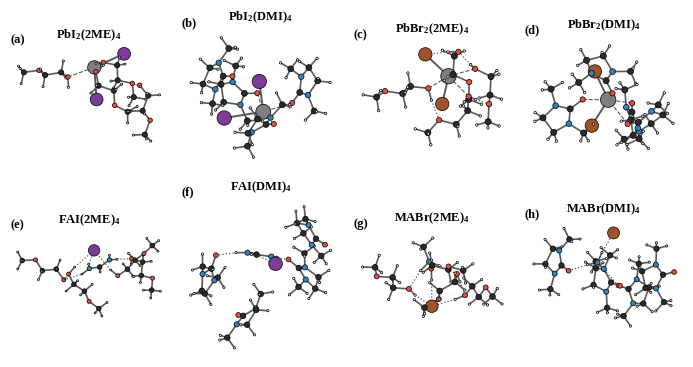

In [5]:
try:
    import ase  # noqa: F401
    HAVE_ASE = True
except ImportError:
    HAVE_ASE = False
    print("ase o'rnatilmagan — Rasm 1 va Rasm S2 o'tkazib yuboriladi (o'rnatish: pip install ase)")
if HAVE_ASE:
    from ase.io import read as ase_read
    from ase.data import covalent_radii, atomic_numbers
    
    ATOM_COLORS = {"Pb": "#7f7f7f", "I": "#7d3c98", "Br": "#a0522d", "O": "#e74c3c",
                   "N": "#2e86c1", "C": "#2b2b2b", "H": "#f2f2f2"}
    
    
    def key_distances(atoms):
        """Pb–O, Pb–X, N–H···O, O–H···X va N···X masofalari (Å)"""
        sym = np.array(atoms.get_chemical_symbols())
        D = atoms.get_all_distances()
        idx = lambda *s: np.where(np.isin(sym, s))[0]
        X, Pb, O, N, H = idx("I", "Br"), idx("Pb"), idx("O"), idx("N"), idx("H")
        out = {}
        if len(Pb):
            dpo = np.sort(D[np.ix_(Pb, O)].min(axis=0))
            out["Pb–O (o'rtacha)"] = dpo[dpo < 3.2].mean() if (dpo < 3.2).any() else np.nan
            out["Pb–X (o'rtacha)"] = D[np.ix_(Pb, X)].mean()
        owner = {h: np.argmin(np.where(np.arange(len(sym)) == h, 9, D[h])) for h in H}
        nh = [h for h in H if sym[owner[h]] == "N"]
        oh = [h for h in H if sym[owner[h]] == "O"]
        if nh and len(O):
            d = D[np.ix_(nh, O)].min(axis=1)
            out["N–H···O (eng qisqa)"] = d.min() if d.min() < 2.6 else np.nan
            out["N–H···O soni (< 2.2 Å)"] = int((d < 2.2).sum())
        if oh and len(X):
            d = D[np.ix_(oh, X)].min(axis=1)
            out["O–H···X (eng qisqa)"] = d.min() if d.min() < 3.2 else np.nan
            out["O–H···X soni (< 3.0 Å)"] = int((d < 3.0).sum())
        if len(N) and len(X):
            out["N···X (eng qisqa)"] = D[np.ix_(N, X)].min()
        return out
    
    
    def euler(rot):
        R = np.eye(3)
        for tok in rot.split(","):
            ang, ax_ = float(tok[:-1]), tok[-1]
            t = np.radians(ang); c_, s_ = np.cos(t), np.sin(t)
            M = {"x": [[1, 0, 0], [0, c_, -s_], [0, s_, c_]],
                 "y": [[c_, 0, s_], [0, 1, 0], [-s_, 0, c_]],
                 "z": [[c_, -s_, 0], [s_, c_, 0], [0, 0, 1]]}[ax_]
            R = np.array(M) @ R
        return R
    
    
    def draw_molecule(ax, atoms, rot):
        """ball-and-stick: kovalent bog'lar — yaxlit, Pb–O/Pb–X — uzuq, H-bog'lar — nuqtali"""
        sym = atoms.get_chemical_symbols()
        pos = (atoms.positions - atoms.positions.mean(0)) @ euler(rot).T
        rc = np.array([covalent_radii[atomic_numbers[e]] for e in sym])
        D = atoms.get_all_distances()
        heavy = {"Pb", "I", "Br"}
        seg = []
        for i in range(len(sym)):
            for j in range(i):
                si, sj, d = sym[i], sym[j], D[i, j]
                pair = {si, sj}
                if not (pair & heavy) and d < 1.15 * (rc[i] + rc[j]):
                    seg.append((i, j, "-", 1.2))
                elif "Pb" in pair and pair & {"O"} and d < 3.0:
                    seg.append((i, j, "--", 0.8))
                elif "Pb" in pair and pair & {"I", "Br"} and d < 3.6:
                    seg.append((i, j, "-", 1.4))
                elif "H" in pair and pair & {"O", "I", "Br"} and pair != {"H", "O"} or (pair == {"H", "O"} and d > 1.3):
                    h = i if si == "H" else j
                    acc = j if h == i else i
                    donor = np.argmin(np.where(np.arange(len(sym)) == h, 9, D[h]))
                    lim = 2.3 if sym[acc] == "O" else 3.0
                    if sym[donor] in ("N", "O") and donor != acc and d < lim:
                        seg.append((i, j, ":", 0.9))
        for i, j, ls, lw in sorted(seg, key=lambda t: pos[t[0], 2] + pos[t[1], 2]):
            ax.plot(pos[[i, j], 0], pos[[i, j], 1], ls, color="0.35", lw=lw, zorder=1,
                    solid_capstyle="round")
        for k in np.argsort(pos[:, 2]):
            r = 0.32 * rc[k] + (0.15 if sym[k] in heavy else 0)
            ax.add_patch(plt.Circle(pos[k, :2], r, fc=ATOM_COLORS.get(sym[k], "#ccc"),
                                    ec="k", lw=0.5, zorder=2 + k / len(sym)))
        ax.set_aspect("equal"); ax.autoscale_view()
        pad = 0.8
        ax.set_xlim(pos[:, 0].min() - pad, pos[:, 0].max() + pad)
        ax.set_ylim(pos[:, 1].min() - pad, pos[:, 1].max() + pad)
    
    
    
    panels = []
    for pre, lab, title in FIG1_PANELS:
        p = data.get(pre, {}).get(lab)
        xyz = files_of(p)[2] if p else None
        if not xyz:
            print(f"Rasm 1: {pre} {lab} geometriyasi yo'q")
        panels.append((title, ase_read(xyz) if xyz else None))
    
    if any(at is not None for _, at in panels):
        nc1 = 4; nr1 = int(np.ceil(len(panels) / nc1))
        fig, axs = plt.subplots(nr1, nc1, figsize=(W2, 1.9 * nr1), squeeze=False)
        for i, (title, at) in enumerate(panels):          # harf FIG1_PANELS tartibida qat'iy
            ax = axs.flat[i]
            if at is not None:
                draw_molecule(ax, at, FIG1_ROTATION)
            else:
                ax.text(0.5, 0.5, "not computed", ha="center", va="center", transform=ax.transAxes, color="0.5")
            ax.set_axis_off(); ax.set_title(title, fontsize=9)
            panel_label(ax, i, x=0.0, y=1.0)
        for ax in axs.flat[len(panels):]:
            ax.set_visible(False)
        fig.tight_layout()
        save(fig, "fig1_structures")
        plt.show()
else:
    print("ase yo'q — bu katak o'tkazildi")


saqlandi: /media/doston/72f1eff3-bf18-4476-8539-c8566520c822/FACsPbI3_VASP/FACsPbI3/ORCA/2ME-DMI/figures/fig1_structures.pdf / .png


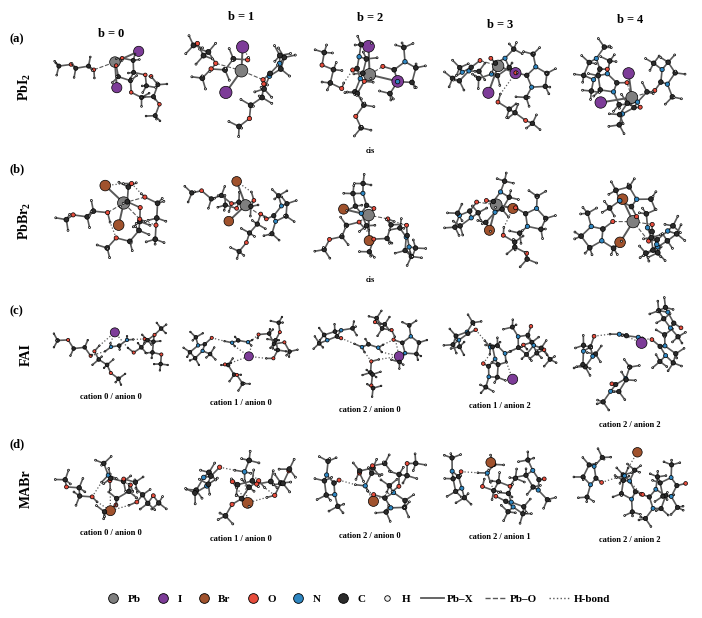

In [6]:
if HAVE_ASE:
    # Rasm 1: har bir prekursor — bitta qator, ustunlar b = 0...n;
    # har b da eng past G ga ega izomer chiziladi
    def iso_tag(lab):
        m = re.search(r"c(\d)a(\d)", lab)
        if m:
            return f"cation {m.group(1)} / anion {m.group(2)}"
        return {"cis": "cis", "trans": "trans"}.get(lab.split("_")[-1], "")
    
    
    rows_fig1 = []
    for pre in PRECURSORS:
        if pre not in data:
            continue
        row = []
        for b in range(N_SITES[pre] + 1):
            best = None
            for lab, p in data[pre].items():
                if b_of(lab) != b or not files_of(p)[2]:
                    continue
                try:
                    g = read_G(p)["G_kJ"]
                except (FileNotFoundError, RuntimeError):
                    g = np.inf
                if best is None or g < best[2]:
                    best = (lab, p, g)
            row.append(best)
        rows_fig1.append((pre, row))
    
    if rows_fig1:
        ncol = max(N_SITES[p] for p, _ in rows_fig1) + 1
        fig, axs = plt.subplots(len(rows_fig1), ncol, figsize=(W2, 1.55 * len(rows_fig1)), squeeze=False)
        for r, (pre, row) in enumerate(rows_fig1):
            for c in range(ncol):
                ax = axs[r, c]
                ax.set_axis_off()
                if r == 0:
                    ax.set_title(f"$b$ = {c}", fontsize=9)
                if c >= len(row):
                    continue
                if row[c] is None:
                    ax.text(0.5, 0.5, "not computed", ha="center", va="center",
                            transform=ax.transAxes, color="0.5", fontsize=7)
                    continue
                lab, p, _ = row[c]
                draw_molecule(ax, ase_read(files_of(p)[2]), FIG1_ROTATION)
                tag = iso_tag(lab)
                if tag:
                    ax.text(0.5, -0.02, tag, ha="center", va="top", transform=ax.transAxes, fontsize=6)
            axs[r, 0].text(-0.12, 0.5, PRE_TEX[pre], transform=axs[r, 0].transAxes,
                           ha="right", va="center", fontsize=10, rotation=90)
            panel_label(axs[r, 0], r, x=-0.30, y=1.0)
            # legenda: atom ranglari + bog' turlari
        from matplotlib.lines import Line2D
        ATOM_NAMES = {"Pb": "Pb", "I": "I", "Br": "Br", "O": "O", "N": "N", "C": "C", "H": "H"}
        present = set()
        for _, row in rows_fig1:
            for x in row:
                if x:
                    present |= set(ase_read(files_of(x[1])[2]).get_chemical_symbols())
        h_atoms = [Line2D([], [], marker="o", ls="", ms=7 if e not in ("H",) else 4,
                          mfc=ATOM_COLORS[e], mec="k", mew=0.6, label=ATOM_NAMES[e])
                   for e in ATOM_COLORS if e in present]
        h_bonds = [Line2D([], [], color="0.35", lw=1.3, ls="-",  label="Pb–X"),
                   Line2D([], [], color="0.35", lw=1.0, ls="--", label="Pb–O"),
                   Line2D([], [], color="0.35", lw=1.0, ls=":",  label="H-bond")]
        fig.tight_layout(w_pad=0.3, h_pad=0.6, rect=(0, 0.07, 1, 1))
        fig.legend(handles=h_atoms + h_bonds, loc="lower center", bbox_to_anchor=(0.5, 0.0),
                   ncol=len(h_atoms) + len(h_bonds), frameon=False, handletextpad=0.3,
                   columnspacing=1.0, fontsize=8)
        save(fig, "fig1_structures")
        plt.show()
else:
    print("ase yo'q — bu katak o'tkazildi")


### Rasm S2 — asosiy masofalarning b ga bog'liqligi

Rasm S2 ma'lumotlari (Å)


,prekursor,label,b,Pb–O (o'rtacha),Pb–X (o'rtacha),O–H···X (eng qisqa),O–H···X soni (< 3.0 Å),N···X (eng qisqa),N–H···O (eng qisqa),N–H···O soni (< 2.2 Å)
0,PbI2,b0,0,2.68,3.10,3.03,0.0,NaN,NaN,NaN
1,PbI2,b1,1,2.76,3.07,2.78,1.0,3.94,NaN,NaN
2,PbI2,b2_cis,2,2.80,3.12,3.04,0.0,4.06,NaN,NaN
3,PbI2,b2_trans,2,2.62,3.11,NaN,0.0,4.07,NaN,NaN
4,PbI2,b3,3,2.59,3.14,2.79,1.0,3.85,NaN,NaN
5,PbI2,b4,4,2.57,3.16,NaN,NaN,4.02,NaN,NaN
6,PbBr2,b0,0,2.64,2.86,2.35,1.0,NaN,NaN,NaN
7,PbBr2,b1,1,2.79,2.86,2.68,1.0,5.34,NaN,NaN
8,PbBr2,b2_cis,2,2.72,2.81,NaN,0.0,3.96,NaN,NaN
9,PbBr2,b2_trans,2,2.68,2.84,2.49,1.0,3.82,NaN,NaN


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saqlandi: /media/doston/72f1eff3-bf18-4476-8539-c8566520c822/FACsPbI3_VASP/FACsPbI3/ORCA/2ME-DMI/figures/figS2_geometry_vs_b.pdf / .png


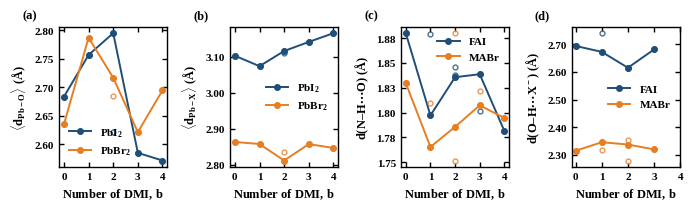

In [7]:
if HAVE_ASE:
    dall = []
    for pre, sp in data.items():
        for lab, p in sp.items():
            xyz = files_of(p)[2]
            if xyz:
                g = _CACHE.get(p, {}).get("G_kJ", np.nan)
                dall.append(dict(prekursor=pre, label=lab, b=b_of(lab), G_kJ=g, **key_distances(ase_read(xyz))))
    dist_all = pd.DataFrame(dall)
    dist_all.to_csv(f"{TABDIR}/figS2_distances_all.csv", index=False)
    print("Rasm S2 ma'lumotlari (Å)")
    display(dist_all.drop(columns="G_kJ").round(2))
    
    S2_PANELS = [("Pb–O (o'rtacha)", r"$\langle d_\mathrm{Pb-O} \rangle$ (Å)", ["PbI2", "PbBr2"]),
                 ("Pb–X (o'rtacha)", r"$\langle d_\mathrm{Pb-X} \rangle$ (Å)", ["PbI2", "PbBr2"]),
                 ("N–H···O (eng qisqa)", r"$d$(N–H$\cdots$O) (Å)", ["FAI", "MABr"]),
                 ("O–H···X (eng qisqa)", r"$d$(O–H$\cdots$X$^-$) (Å)", ["FAI", "MABr"])]
    S2_PANELS = [q for q in S2_PANELS if q[0] in dist_all.columns
                 and dist_all[dist_all.prekursor.isin(q[2])][q[0]].notna().any()]
    if S2_PANELS:
        fig, axs = plt.subplots(1, len(S2_PANELS), figsize=(W2, 2.2), squeeze=False)
        for i, (col, ylab, pl) in enumerate(S2_PANELS):
            ax = axs[0, i]
            for j, pre in enumerate(pl):
                d = dist_all[(dist_all.prekursor == pre) & dist_all[col].notna()]
                if not len(d):
                    continue
                c = COLORS[[0, 4][j % 2]]
                ax.plot(d.b, d[col], "o", ms=3.5, mfc="white", mec=c, alpha=0.8)        # barcha izomerlar
                best = d.loc[d.groupby("b")["G_kJ"].idxmin()] if d.G_kJ.notna().all() else d.groupby("b", as_index=False)[col].mean()
                ax.plot(best.b, best[col], "o-", ms=4, color=c, label=PRE_TEX[pre])      # eng barqaror izomer
            ax.set_xlabel("Number of DMI, $b$")
            ax.set_ylabel(ylab)
            ax.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%.2f"))
            ax.set_xticks(range(5))
            ax.legend()
            panel_label(ax, i, x=-0.34)
        fig.tight_layout()
        save(fig, "figS2_geometry_vs_b")
        plt.show()
else:
    print("ase yo'q — bu katak o'tkazildi")


## 3. Termodinamik model
### Tenglamalar (2)–(4): ligand almashinish erkin energiyalari ΔG_b va β_b

In [8]:
def exchange_table(pre, species, n, shift=0.0, lig=None):
    """(3) ΔG_b,i = G[M(2ME)n-b(DMI)b] - G[M(2ME)n] + b[G(2ME) - G(DMI)];  (4) β_b"""
    lig = lig or LIG[pre]
    G2, GD = read_G(lig["2ME"])["G_kJ"], read_G(lig["DMI"])["G_kJ"]
    ref = read_G(species[next(l for l in species if b_of(l) == 0)])
    rec, beta = [], np.zeros(n + 1)
    for lab, p in species.items():
        try:
            Gc = read_G(p)["G_kJ"]
        except (FileNotFoundError, RuntimeError):
            continue
        b = b_of(lab)
        dG = Gc - ref["G_kJ"] + b * (G2 - GD) + shift * b
        g = WEIGHTS.get(pre, {}).get(lab, 1)
        beta[b] += g * np.exp(-dG / RT)
        rec.append(dict(prekursor=pre, label=lab, b=b, g=g, dG_kJ=dG, dG_per_DMI=dG / b if b else 0.0))
    return pd.DataFrame(rec).sort_values(["b", "label"]), beta


def dG_eff(df):
    """bir xil b dagi izomerlarning Boltsman-effektiv ΔG_b"""
    return df.groupby("b")["dG_kJ"].apply(lambda x: -RT * np.log(np.exp(-x / RT).sum()))


EX, BETA = {}, {}
for pre in data:
    try:
        EX[pre], BETA[pre] = exchange_table(pre, data[pre], N_SITES[pre])
    except (FileNotFoundError, RuntimeError, StopIteration, TypeError, KeyError) as e:
        print(f"{pre}: o'tkazib yuborildi ({e})")
ex_all = pd.concat(EX.values()) if EX else pd.DataFrame()
ex_all.to_csv(f"{TABDIR}/exchange_dG.csv", index=False)

# seriya to'liqligi: (5)-(6) uchun b = 0...n ning hammasi kerak
COMPLETE, rows = {}, []
for pre, df in EX.items():
    have = set(df.b)
    miss_b = [b for b in range(N_SITES[pre] + 1) if b not in have]
    expected = list(WEIGHTS.get(pre, data[pre]))
    miss_lab = [l for l in expected if l not in set(df.label)]
    COMPLETE[pre] = not miss_b
    rows.append(dict(prekursor=pre, hisoblangan=f"{len(df)}/{len(expected)}",
                     yetishmaydigan_b=", ".join(map(str, miss_b)) or "—",
                     tugallanmagan=", ".join(miss_lab) or "—",
                     holat="to'liq" if not miss_b else "TO'LIQ EMAS: Rasm 3-5 da ko'rsatilmaydi"))
for pre in PRECURSORS:
    if pre in data and pre not in EX:
        rows.append(dict(prekursor=pre, hisoblangan="0", yetishmaydigan_b="b0 (mos yozuv)",
                         tugallanmagan="b0", holat="o'qilmadi: b0 tuzilmasining s3 natijasi yo'q"))
print("Seriyalar holati")
display(pd.DataFrame(rows).set_index("prekursor"))
print("Tenglama (3): ΔG_b, kJ/mol")
display(ex_all.round(2))
print("Tenglama (4): β_b")
display(pd.DataFrame({p: pd.Series(b) for p, b in BETA.items()}).T.apply(lambda col: col.map(lambda v: f"{v:.3g}")))

Seriyalar holati


,hisoblangan,yetishmaydigan_b,tugallanmagan,holat
prekursor,,,,
PbI2,6/6,—,—,to'liq
PbBr2,6/6,—,—,to'liq
FAI,9/9,—,—,to'liq
MABr,9/9,—,—,to'liq


Tenglama (3): ΔG_b, kJ/mol


,prekursor,label,b,g,dG_kJ,dG_per_DMI
0,PbI2,b0,0,1,0.00,0.00
1,PbI2,b1,1,4,-22.25,-22.25
2,PbI2,b2_cis,2,4,-33.76,-16.88
3,PbI2,b2_trans,2,2,-21.89,-10.94
4,PbI2,b3,3,4,-34.03,-11.34
5,PbI2,b4,4,1,-33.77,-8.44
0,PbBr2,b0,0,1,0.00,0.00
1,PbBr2,b1,1,4,36.38,36.38
2,PbBr2,b2_cis,2,4,13.95,6.97
3,PbBr2,b2_trans,2,2,26.14,13.07


Tenglama (4): β_b


,0,1,2,3,4
PbI2,1,3.16e+04,3.29e+06,3.67e+06,8.25e+05
PbBr2,1,1.69e-06,0.0145,0.00394,0.000365
FAI,1,0.126,51.1,1.69,0.0371
MABr,1,0.158,0.0268,0.00211,4.13e-05


### Rasm 2 — ΔG_b ning b ga bog'liqligi

saqlandi: /media/doston/72f1eff3-bf18-4476-8539-c8566520c822/FACsPbI3_VASP/FACsPbI3/ORCA/2ME-DMI/figures/fig2_exchange_dG.pdf / .png


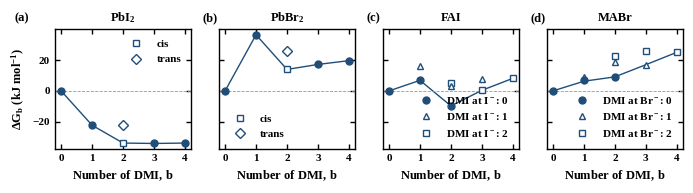

In [9]:
pres = list(EX)
fig, axs = plt.subplots(1, len(pres), figsize=(W2, 2.0), sharey=True, squeeze=False)
for i, pre in enumerate(pres):
    ax, df = axs[0, i], EX[pre]
    eff = dG_eff(df)
    ax.axhline(0, color="0.6", lw=0.6, ls="--")
    ax.plot(eff.index, eff.values, "-", color=COLORS[0], lw=1.0, zorder=1)
    for _, r in df.iterrows():
        ca = re.search(r"c(\d)a(\d)", r.label)
        if ca:     # ion jufti: marker = I- o'rnidagi DMI soni
            hal = "Br" if "Br" in pre else "I"
            a_ = int(ca.group(2)); mk = "o^s"[a_]; lab = rf"DMI at {hal}$^-$: {a_}"
        else:
            mk = {"cis": "s", "trans": "D"}.get(r.label.split("_")[-1], "o")
            lab = {"s": "cis", "D": "trans"}.get(mk)
        ax.plot(r.b, r.dG_kJ, mk, ms=5, mfc="white" if mk != "o" else COLORS[0],
                mec=COLORS[0], zorder=2, label=lab)
    ax.set_xticks(range(N_SITES[pre] + 1))
    ax.set_xlabel("Number of DMI, $b$")
    ax.set_title(PRE_TEX[pre])
    panel_label(ax, i, x=-0.12 if i else -0.3)
    h, l = ax.get_legend_handles_labels()
    if l:
        ax.legend(dict(zip(l, h)).values(), dict(zip(l, h)).keys(), loc="best")
axs[0, 0].set_ylabel(r"$\Delta G_b$ (kJ mol$^{-1}$)")
fig.tight_layout()
save(fig, "fig2_exchange_dG")
plt.show()

### Tenglamalar (5)–(6): to'yinish eruvchanligi va massa balansi
Kalibrlash qiymati (`CALIB`) berilmagan prekursorlar uchun suyultirilgan chegarada nisbiy eruvchanlik S_sat(φ)/S_sat(0) hisoblanadi (bu holda φ* aniqlanmaydi).

In [10]:
def saturation(phi, beta, S_ref):
    n = len(beta) - 1
    b = np.arange(n + 1)
    D0, M0 = C_DMI * phi, C_2ME * (1 - phi)
    kb = S_ref * beta * (C_DMI / C_2ME) ** b
    species = lambda aD, aM: kb * aM ** (n - b) * aD ** b

    def resid(v):
        c = species(*v)
        return [(C_DMI * v[0] + (b * c).sum() - D0) / (D0 + 1e-6),
                (C_2ME * v[1] + ((n - b) * c).sum() - M0) / (M0 + 1e-6)]

    ub = [max(phi, 1e-12), max(1 - phi, 1e-12)]
    v = least_squares(resid, [0.5 * ub[0], 0.5 * ub[1]], bounds=([0, 0], ub),
                      xtol=1e-14, ftol=1e-14, gtol=1e-14).x
    c = species(*v)
    return c.sum(), c


def calibrate(beta, solvent, S_exp):
    n = len(beta) - 1
    phi0, lim = (0.0, C_2ME / n) if solvent == "2ME" else (1.0, C_DMI / n)
    if beta[0 if solvent == "2ME" else n] == 0:
        raise ValueError(f"toza {solvent} uchun kompleks hisoblanmagan")
    if S_exp >= 0.98 * lim:
        raise ValueError(f"S = {S_exp} M massa balansi chegarasidan ({lim:.2f} M) oshadi")
    f = lambda l: np.log(saturation(phi0, beta, np.exp(l))[0]) - np.log(S_exp)
    return np.exp(brentq(f, -120, 120))


PHI = np.linspace(0, 1, 401)
SAT = {}
for pre in [p for p in EX if COMPLETE[p]]:
    solv, S_exp = CALIB[pre]
    curves = {}
    for sh in (0.0, -DG_ERR, DG_ERR):
        _, bt = exchange_table(pre, data[pre], N_SITES[pre], shift=sh)
        s_ref = calibrate(bt, solv, S_exp) if S_exp else 1e-6     # 1e-6 M: suyultirilgan chegara
        res = [saturation(p, bt, s_ref) for p in PHI]
        S = np.array([r[0] for r in res]); Cb = np.array([r[1] for r in res])
        if not S_exp:
            S = S / S[0]
        curves[sh] = (S, Cb)
    SAT[pre] = dict(S=curves[0.0][0], C=curves[0.0][1], calibrated=bool(S_exp),
                    lo=np.minimum(curves[-DG_ERR][0], curves[DG_ERR][0]),
                    hi=np.maximum(curves[-DG_ERR][0], curves[DG_ERR][0]),
                    band={sh: v[0] for sh, v in curves.items()})
    if S_exp:
        print(f"{pre}: S(toza 2-ME) = {SAT[pre]['S'][0]:.3g} M, S(toza DMI) = {SAT[pre]['S'][-1]:.3g} M")
    else:
        print(f"{pre}: kalibrlanmagan — nisbiy S(toza DMI)/S(toza 2-ME) = {SAT[pre]['S'][-1]:.3g}")
pd.DataFrame({f"{p}": v["S"] for p, v in SAT.items()}, index=np.round(100 * PHI, 2)).rename_axis(
    "phi_vol%").to_csv(f"{TABDIR}/fig3_Ssat.csv")

PbI2: kalibrlanmagan — nisbiy S(toza DMI)/S(toza 2-ME) = 1.72e+05
PbBr2: kalibrlanmagan — nisbiy S(toza DMI)/S(toza 2-ME) = 0.000103
FAI: kalibrlanmagan — nisbiy S(toza DMI)/S(toza 2-ME) = 0.0105
MABr: kalibrlanmagan — nisbiy S(toza DMI)/S(toza 2-ME) = 1.17e-05


### Rasm 4 — solvat komplekslar ulushi c_b/S_sat

saqlandi: /media/doston/72f1eff3-bf18-4476-8539-c8566520c822/FACsPbI3_VASP/FACsPbI3/ORCA/2ME-DMI/figures/fig4_species_fractions.pdf / .png


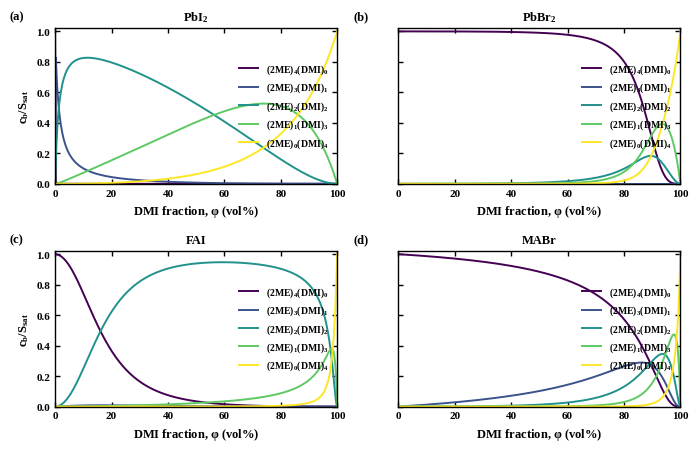

In [11]:
pres = list(SAT)
nc = min(2, len(pres)) or 1; nr = int(np.ceil(len(pres) / nc))
if pres:
    fig, axs = plt.subplots(nr, nc, figsize=(W2, 2.3 * nr), squeeze=False, sharey=True)
    for i, pre in enumerate(pres):
        ax, s = axs.flat[i], SAT[pre]
        n = N_SITES[pre]
        frac = s["C"] / s["C"].sum(1, keepdims=True)
        cmap = plt.get_cmap("viridis")
        for b in range(n + 1):
            ax.plot(100 * PHI, frac[:, b], color=cmap(b / n), label=rf"(2ME)$_{{{n-b}}}$(DMI)$_{{{b}}}$")
        ax.set_xlim(0, 100); ax.set_ylim(0, 1.02)
        ax.set_xlabel(r"DMI fraction, $\varphi$ (vol%)")
        if i % nc == 0:
            ax.set_ylabel(r"$c_b / S_\mathrm{sat}$")
        ax.set_title(PRE_TEX[pre])
        ax.legend(loc="center right", fontsize=7)
        panel_label(ax, i)
    for ax in axs.flat[len(pres):]:
        ax.set_visible(False)
    fig.tight_layout()
    save(fig, "fig4_species_fractions")
    plt.show()

## 4. Eruvchanlik chegarasi va kalibrlash — tenglama (7)

In [12]:
def crossings(S, c):
    """S(φ) = c tenglamaning barcha ildizlari (chiziqli interpolyatsiya bilan aniqlashtirilgan)"""
    f = S - c
    out = []
    for i in np.where(np.sign(f[:-1]) * np.sign(f[1:]) < 0)[0]:
        out.append(PHI[i] - f[i] * (PHI[i + 1] - PHI[i]) / (f[i + 1] - f[i]))
    return out


def soluble_text(S, c):
    ok = S >= c
    if ok.all():
        return "barcha tarkiblarda eriydi"
    if not ok.any():
        return "hech qaysi tarkibda erimaydi"
    segs, start = [], None
    for i, v in enumerate(ok):
        if v and start is None:
            start = i
        if (not v or i == len(ok) - 1) and start is not None:
            end = i if v else i - 1
            segs.append(f"{100*PHI[start]:.0f}–{100*PHI[end]:.0f} % DMI")
            start = None
    return "; ".join(segs)


ratio = lambda p: "∞" if p == 0 else f"{(1-p)/p:.2f}:1"
tab, THR = [], {}
for pre, s in SAT.items():
    if not s["calibrated"]:
        print(f"{pre}: CALIB berilmagan — φ* hisoblanmadi")
        continue
    c = C_TARGET[pre]
    roots = crossings(s["S"], c)
    rb = {sh: crossings(s["band"][sh], c) for sh in (-DG_ERR, DG_ERR)}
    THR[pre] = dict(roots=roots, band=rb, soluble=s["S"] >= c, c=c)
    eff = dG_eff(EX[pre]); n = N_SITES[pre]
    tab.append({
        "Prekursor": pre, "n": n, "c_target, M": c,
        "ΔG_n, kJ/mol": round(eff.get(n, np.nan), 1), "ΔG_n/n, kJ/mol": round(eff.get(n, np.nan) / n, 1),
        "φ*, hajm %": "; ".join(f"{100*r:.1f}" for r in roots) or "—",
        f"φ* (ΔG ±{DG_ERR:g}), %": "; ".join(f"{sh:+g}: " + (", ".join(f"{100*r:.1f}" for r in rb[sh]) or "kesishmaydi") for sh in rb),
        "2-ME:DMI chegarasi (V/V)": "; ".join(ratio(r) for r in roots) or "—",
        "DMI:M (mol)": "; ".join(f"{C_DMI*r/c:.2f}" for r in roots) or "—",
        "Erish sohasi": soluble_text(s["S"], c),
    })
thresholds = pd.DataFrame(tab).set_index("Prekursor") if tab else pd.DataFrame()
thresholds.to_csv(f"{TABDIR}/thresholds.csv")
print("Tenglama (7): eruvchanlik chegaralari (Rasm 3 va Rasm 5 ma'lumotlari)")
display(thresholds)

PbI2: CALIB berilmagan — φ* hisoblanmadi
PbBr2: CALIB berilmagan — φ* hisoblanmadi
FAI: CALIB berilmagan — φ* hisoblanmadi
MABr: CALIB berilmagan — φ* hisoblanmadi
Tenglama (7): eruvchanlik chegaralari (Rasm 3 va Rasm 5 ma'lumotlari)


""


### Rasm 3 — S_sat(φ), noaniqlik sohasi, c_target va φ*

saqlandi: /media/doston/72f1eff3-bf18-4476-8539-c8566520c822/FACsPbI3_VASP/FACsPbI3/ORCA/2ME-DMI/figures/fig3_saturation_threshold.pdf / .png


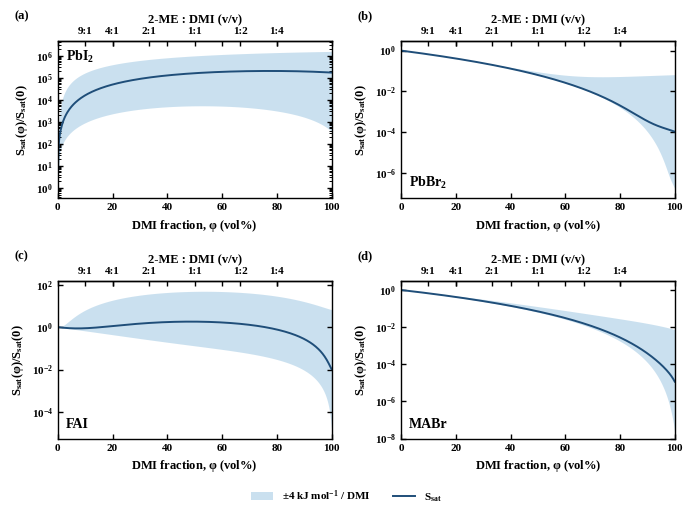

In [13]:
if pres:
    fig, axs = plt.subplots(nr, nc, figsize=(W2, 2.6 * nr), squeeze=False)
    for i, pre in enumerate(pres):
        ax, s = axs.flat[i], SAT[pre]
        x = 100 * PHI
        if s["calibrated"]:
            c = C_TARGET[pre]
            ins = s["S"] < c
            edges = np.flatnonzero(np.diff(np.r_[0, ins.astype(int), 0]))
            for k, (i0, i1) in enumerate(zip(edges[::2], edges[1::2])):
                ax.axvspan(x[i0], x[min(i1, len(x) - 1)], color="0.9", lw=0, label="Insoluble" if k == 0 else None)
        ax.fill_between(x, s["lo"], s["hi"], color=COLORS[1], alpha=0.25, lw=0,
                        label=rf"$\pm${DG_ERR:g} kJ mol$^{{-1}}$ / DMI")
        ax.semilogy(x, s["S"], color=COLORS[0], label=r"$S_\mathrm{sat}$")
        ymin = max(s["lo"].min() / 3, 1e-8); ymax = s["hi"].max() * 3
        if s["calibrated"]:
            ymin = min(ymin, c / 3); ymax = max(ymax, c * 3)
            ax.axhline(c, color=COLORS[5], lw=0.8, ls="--", label=r"$c_\mathrm{target}$")
            ax.text(98, c / 1.25, f"{c:g} M", color=COLORS[5], fontsize=8, ha="right", va="top")
            for r in crossings(s["S"], c):
                ax.axvline(100 * r, color="k", lw=0.8, ls=":")
                ax.text(100 * r + 1, ymin * (ymax / ymin) ** 0.06, rf"$\varphi^*$ = {100*r:.0f} vol%",
                        fontsize=8, ha="left", va="bottom")
            ax.set_ylabel(r"$S_\mathrm{sat}$ (mol L$^{-1}$)")
        else:
            ax.set_ylabel(r"$S_\mathrm{sat}(\varphi) / S_\mathrm{sat}(0)$")
        ax.set_ylim(ymin, ymax); ax.set_xlim(0, 100)
        ax.set_xlabel(r"DMI fraction, $\varphi$ (vol%)")
        # prekursor nomi: egri chiziqdan uzoqroq burchakka
        yl = np.log10(s["S"][:60]); yr = (yl - np.log10(ymin)) / (np.log10(ymax) - np.log10(ymin))
        top = yr.mean() < 0.6
        ax.text(0.03, 0.95 if top else 0.05, PRE_TEX[pre], transform=ax.transAxes, fontsize=10,
                va="top" if top else "bottom", ha="left")
        ratio_axis(ax)
        panel_label(ax, i, y=1.12)
    for ax in axs.flat[len(pres):]:
        ax.set_visible(False)
    hl = {}
    for ax in axs.flat[:len(pres)]:
        for h, l in zip(*ax.get_legend_handles_labels()):
            hl.setdefault(l, h)
    if any(SAT[p]["calibrated"] for p in pres):
        hl[r"$\varphi^*$"] = plt.Line2D([], [], color="k", lw=0.8, ls=":")
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.legend(hl.values(), hl.keys(), loc="lower center", ncol=len(hl), bbox_to_anchor=(0.5, 0.0))
    save(fig, "fig3_saturation_threshold")
    plt.show()

### Rasm 5 — eruvchanlik oynalari va ΔG_n/n

saqlandi: /media/doston/72f1eff3-bf18-4476-8539-c8566520c822/FACsPbI3_VASP/FACsPbI3/ORCA/2ME-DMI/figures/fig5_solubility_window.pdf / .png


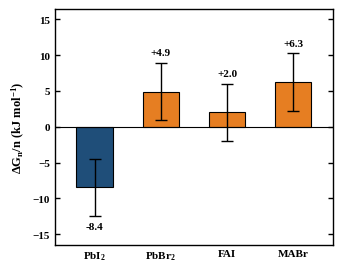

In [14]:
# Rasm 5: bitta DMI ga to'g'ri keladigan to'liq almashinish energiyasi ΔG_n/n
pres_all = [p for p in EX if COMPLETE[p]]
if pres_all:
    vals = np.array([dG_eff(EX[p]).get(N_SITES[p], np.nan) / N_SITES[p] for p in pres_all])
    x = np.arange(len(pres_all))
    fig, ax = plt.subplots(figsize=(W2 / 2, 2.8))
    ax.bar(x, vals, width=0.55, yerr=DG_ERR, capsize=4,
           color=[COLORS[0] if v < 0 else COLORS[4] for v in vals],
           edgecolor="k", lw=0.8, error_kw=dict(lw=1.0, capthick=1.0))
    ax.axhline(0, color="k", lw=0.8)
    for xi, v in zip(x, vals):                       # qiymat yozuvi ustun ichida/ustida
        off = DG_ERR + 0.8
        ax.text(xi, v + (off if v >= 0 else -off), f"{v:+.1f}",
                ha="center", va="bottom" if v >= 0 else "top", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels([PRE_TEX[p] for p in pres_all])
    ax.tick_params(axis="x", length=0)
    ax.set_ylabel(r"$\Delta G_n / n$ (kJ mol$^{-1}$)")
    lim = np.nanmax(np.abs(vals)) + DG_ERR + 4
    ax.set_ylim(-lim, lim)
    ax.set_xlim(-0.6, len(pres_all) - 0.4)
    fig.tight_layout()
    save(fig, "fig5_solubility_window")
    plt.show()

### Rasm S1 — koordinatsiya soni va dielektrik muhit sezgirligi

In [15]:
if not VARIANTS:
    print("VARIANTS bo'sh — Rasm S1 uchun n = 3 va ε = 37.6 hisoblari kerak (0-katakda papkalarni ko'rsating)")
else:
    bases = [b for b in dict.fromkeys(v[0] for v in VARIANTS.values()) if b in SAT]
    fig, axs = plt.subplots(1, len(bases), figsize=(W2 / 2 * len(bases), 2.5), squeeze=False)
    for i, base in enumerate(bases):
        ax = axs[0, i]
        ax.semilogy(100 * PHI, SAT[base]["S"], color="k", label=f"Baseline ($n$ = {N_SITES[base]})")
        for j, (name, (b0, n, vdir)) in enumerate(VARIANTS.items()):
            if b0 != base:
                continue
            sp = discover(vdir, base)
            if not sp:
                print(f"{name}: {vdir} da natija topilmadi"); continue
            _, bt = exchange_table(base, sp, n)
            solv, S_exp = CALIB[base]
            s_ref = calibrate(bt, solv, S_exp) if S_exp else 1e-6
            S = np.array([saturation(p, bt, s_ref)[0] for p in PHI])
            ax.semilogy(100 * PHI, S if S_exp else S / S[0], color=COLORS[(j + 1) % 6], ls="--", label=name)
        if SAT[base]["calibrated"]:
            ax.axhline(C_TARGET[base], color=COLORS[5], lw=0.8, ls="--")
        ax.set(xlim=(0, 100), xlabel=r"DMI fraction, $\varphi$ (vol%)",
               ylabel=r"$S_\mathrm{sat}$ (mol L$^{-1}$)" if SAT[base]["calibrated"] else r"$S_\mathrm{sat}/S_\mathrm{sat}(0)$",
               title=PRE_TEX[base])
        ax.legend()
        panel_label(ax, i)
    fig.tight_layout()
    save(fig, "figS1_sensitivity")
    plt.show()

VARIANTS bo'sh — Rasm S1 uchun n = 3 va ε = 37.6 hisoblari kerak (0-katakda papkalarni ko'rsating)


## 5. Sezgirlik testlari — Qo'shimcha materiallar (taqrizchilarga javob)
Bu bo'lim taqrizchilar savollariga javob uchun qo'shimcha hisoblarni o'qiydi; fayllar topilmasa, tegishli jadval o'tkazib yuboriladi.

| Natija | Fayllar | Savol |
| --- | --- | --- |
| **Jadval S1** — termokimyo darajasi: A (r²SCAN-3c E + xTB termo) va B (to'liq r²SCAN-3c/SMD) | `*_s4_r2freq.out` | R1-1, R2-1 |
| **Jadval S2** — quasi-RRHO sezgirligi (RRHO; ω₀ = 50, 100, 150 cm⁻¹) | `*_s4_r2freq.out` | R1-1 |
| **Jadval S3** — uzluksiz muhit modeli, tarkibi va elektron tuzilish metodi | `*_s5_cpcm2me.out`, `*_s5_cpcmdmi.out`, `*_s6_wb97mv.out` | R1-5, R2-1 |
| **Rasm S3** — nisbiy eruvchanlikning S_ref ga bog'liqligi | — | R1-2 |

In [16]:
# Jadval S1, S2: to'liq r2SCAN-3c/SMD termokimyosi (s4) va quasi-RRHO sezgirligi
H_, KB_, C_ = 6.62607015e-34, 1.380649e-23, 2.99792458e10
R_ = 8.314462618e-3


def s4_file(path, suffix="s4_r2freq"):
    f = sorted(glob.glob(os.path.join(path, f"*_{suffix}.out")))
    return f[0] if f else None


def read_s4(path):
    f = s4_file(path)
    if not f:
        return None
    txt = open(f, errors="ignore").read()
    g = re.findall(r"G-E\(el\)\s+\.\.\.\s+(-?\d+\.\d+)\s+Eh", txt)
    if not g or "ORCA TERMINATED NORMALLY" not in txt:
        return None
    E = float(re.findall(r"FINAL SINGLE POINT ENERGY\s+(-?\d+\.\d+)", txt)[-1])
    nu, started = [], False
    for line in txt[txt.rfind("VIBRATIONAL FREQUENCIES"):].splitlines()[1:]:
        m = re.match(r"\s*\d+:\s+(-?\d+\.\d+)\s+cm\*\*-1", line)
        if m:
            started = True
            if abs(float(m.group(1))) > 1e-3:
                nu.append(float(m.group(1)))
        elif started and line.strip():
            break
    return dict(E=E * HA, g=float(g[-1]) * HA, nu=nu, n_imag=sum(v < 0 for v in nu))


def gvib(nu, w0=None):
    """tebranma erkin energiya, kJ/mol; w0=None -> RRHO, aks holda Grimme qRRHO (entropiya)"""
    Bav, G = 1e-44, 0.0
    for v in nu:
        if v <= 0:
            continue
        x = H_ * C_ * v / (KB_ * T)
        Sh = R_ * (x / np.expm1(x) - np.log(-np.expm1(-x)))
        S = Sh
        if w0:
            mu = H_ / (8 * np.pi ** 2 * C_ * v)
            mu_p = mu * Bav / (mu + Bav)
            Sr = R_ * (0.5 + np.log(np.sqrt(8 * np.pi ** 3 * mu_p * KB_ * T / H_ ** 2)))
            w = 1 / (1 + (w0 / v) ** 4)
            S = w * Sh + (1 - w) * Sr
        G += R_ * T * (x / 2 + x / np.expm1(x)) - T * S
    return G


LIG4 = {nm: read_s4(os.path.join(ROOT, nm)) for nm in ("2ME", "DMI")}
rows1, rows2 = [], []
for pre in data:
    ref_lab = next(l for l in data[pre] if b_of(l) == 0)
    P0 = read_s4(data[pre][ref_lab])
    if not (P0 and LIG4["2ME"] and LIG4["DMI"]):
        print(f"{pre}: b0 yoki erituvchilar uchun s4 yo'q — o'tkazildi"); continue
    A2, AD, A0 = read_G(LIG[pre]["2ME"]), read_G(LIG[pre]["DMI"]), read_G(data[pre][ref_lab])
    for lab, p in data[pre].items():
        Pc = read_s4(p)
        if lab == ref_lab or not Pc:
            continue
        b, Ac = b_of(lab), read_G(p)
        dA = lambda k: (Ac[k] - A0[k] + b * (A2[k] - AD[k])) * HA
        dB = lambda k: Pc[k] - P0[k] + b * (LIG4["2ME"][k] - LIG4["DMI"][k])
        A, B = dA("E_Eh") + dA("GmE_Eh"), dB("E") + dB("g")
        # mavhum modalarni |nu| — haqiqiy past chastota deb olish (qRRHO, w0 = 100): G ga qo'shimcha had
        add = lambda P: gvib([-v for v in P["nu"] if v < 0], 100.0)
        corr = add(Pc) - add(P0) + b * (add(LIG4["2ME"]) - add(LIG4["DMI"]))
        rows1.append(dict(prekursor=pre, label=lab, b=b, A=A, B=B, B_minus_A=B - A,
                          geometriya=dB("E") - dA("E_Eh"), termokimyo=dB("g") - dA("GmE_Eh"),
                          n_imag_s4=Pc["n_imag"], n_imag_ref=P0["n_imag"],
                          imag_nu=" ".join(f"{v:.0f}" for v in Pc["nu"] if v < 0),
                          B_imag_real=B + corr, imag_tuzatma=corr))
        gv = {}
        for key, w0 in [("RRHO", None), ("q50", 50.0), ("q100", 100.0), ("q150", 150.0)]:
            gv[key] = (gvib(Pc["nu"], w0) - gvib(P0["nu"], w0)
                       + b * (gvib(LIG4["2ME"]["nu"], w0) - gvib(LIG4["DMI"]["nu"], w0)))
        rows2.append(dict(prekursor=pre, label=lab, b=b, RRHO=gv["RRHO"] - gv["q100"],
                          qRRHO_50=gv["q50"] - gv["q100"], qRRHO_150=gv["q150"] - gv["q100"]))

if rows1:
    TS1, TS2 = pd.DataFrame(rows1), pd.DataFrame(rows2)
    TS1.to_csv(f"{TABDIR}/tableS1_thermo_level.csv", index=False)
    TS2.to_csv(f"{TABDIR}/tableS2_qrrho.csv", index=False)
    imag = {k: v["n_imag"] for k, v in LIG4.items()}
    imag.update({f"{pre}_{l}": read_s4(p)["n_imag"] for pre in data for l, p in data[pre].items() if read_s4(p)})
    print("Jadval S1. ΔG_b,i (kJ/mol): A — r²SCAN-3c E + GFN2-xTB termo (qo'lyozma); B — to'liq r²SCAN-3c/SMD(2-ME)")
    display(TS1.round(1))
    print("Jadval S2. ΔG_b ning qRRHO(ω0 = 100 cm⁻¹) dan farqi, kJ/mol")
    display(TS2.round(2))
    bad = {k: v for k, v in imag.items() if v}
    print("s4: mavhum chastota qolgan tuzilmalar:", bad if bad else "yo'q — hammasi minimum")
    print(f"max |B − A| = {TS1.B_minus_A.abs().max():.1f} kJ/mol;  max |ω0 50–150| = "
          f"{TS2[['qRRHO_50', 'qRRHO_150']].abs().values.max():.1f};  max |RRHO| = {TS2.RRHO.abs().max():.1f} kJ/mol")
    print(f"mavhum modalarni |ν| deb olish ta'siri: max |B_imag_real − B| = {TS1.imag_tuzatma.abs().max():.1f} kJ/mol")

Jadval S1. ΔG_b,i (kJ/mol): A — r²SCAN-3c E + GFN2-xTB termo (qo'lyozma); B — to'liq r²SCAN-3c/SMD(2-ME)


,prekursor,label,b,A,B,B_minus_A,geometriya,termokimyo,n_imag_s4,n_imag_ref,imag_nu,B_imag_real,imag_tuzatma
0,PbI2,b2_cis,2,-33.8,-35.9,-2.2,0.0,-2.2,0,0,,-35.9,0.0
1,PbI2,b4,4,-33.8,-35.2,-1.5,0.0,-1.5,0,0,,-35.2,0.0
2,PbBr2,b1,1,36.4,25.6,-10.8,0.0,-10.8,0,1,,27.6,2.0
3,PbBr2,b2_cis,2,13.9,18.8,4.8,0.0,4.8,2,1,-90 -67,17.5,-1.2
4,PbBr2,b4,4,19.6,22.7,3.1,0.1,3.0,1,1,-54,22.8,0.1
5,FAI,b2_c2a0,2,-9.7,-3.7,6.0,0.1,5.9,1,0,-175,-4.0,-0.3
6,FAI,b4_c2a2,4,8.2,28.0,19.8,-0.5,20.3,3,0,-195 -48 -14,22.4,-5.6
7,MABr,b2_c2a0,2,9.2,12.1,3.0,-2.4,5.4,1,1,-83,12.7,0.6
8,MABr,b4_c2a2,4,25.0,21.3,-3.7,0.3,-4.0,0,1,,23.5,2.2


Jadval S2. ΔG_b ning qRRHO(ω0 = 100 cm⁻¹) dan farqi, kJ/mol


,prekursor,label,b,RRHO,qRRHO_50,qRRHO_150
0,PbI2,b2_cis,2,-1.94,-1.02,-0.08
1,PbI2,b4,4,-5.11,-2.00,-0.19
2,PbBr2,b1,1,-9.83,-1.23,0.21
3,PbBr2,b2_cis,2,-2.36,0.25,-0.03
4,PbBr2,b4,4,-5.75,-2.64,0.26
5,FAI,b2_c2a0,2,1.01,1.18,-0.84
6,FAI,b4_c2a2,4,7.22,-0.45,-0.62
7,MABr,b2_c2a0,2,-2.53,0.14,-0.10
8,MABr,b4_c2a2,4,-10.19,-2.35,-0.66


s4: mavhum chastota qolgan tuzilmalar: {'PbBr2_b0': 1, 'PbBr2_b2_cis': 2, 'PbBr2_b4': 1, 'FAI_b2_c2a0': 1, 'FAI_b4_c2a2': 3, 'MABr_b0_c0a0': 1, 'MABr_b2_c2a0': 1}
max |B − A| = 19.8 kJ/mol;  max |ω0 50–150| = 2.6;  max |RRHO| = 10.2 kJ/mol
mavhum modalarni |ν| deb olish ta'siri: max |B_imag_real − B| = 5.6 kJ/mol


In [17]:
# Jadval S3: uzluksiz muhit modeli (CPCM vs SMD), tarkibi (ε 2-ME -> DMI) va metod (ωB97M-V vs r2SCAN-3c)
# Hammasi s2 geometriyalarida yagona nuqta; termal tuzatmalar bir xil bo'lgani uchun farqlarda qisqaradi.
def sp_E(path, suffix):
    f = s4_file(path, suffix)
    if not f or "ORCA TERMINATED NORMALLY" not in open(f, errors="ignore").read():
        return None
    return last_float(f, "FINAL SINGLE POINT ENERGY") * HA


VARS3 = {"SMD": None, "CPCM": "s5_cpcm2me", "CPCM_epsDMI": "s5_cpcmdmi", "wB97M-V": "s6_wb97mv"}


def energies3(path):
    out = {"SMD": read_G(path)["E_Eh"] * HA if files_of(path)[0] else None}
    for k, suf in VARS3.items():
        if suf:
            out[k] = sp_E(path, suf)
    return out


L3 = {nm: energies3(os.path.join(ROOT, nm)) for nm in ("2ME", "DMI")}
rows3 = []
for pre in data:
    ref_lab = next(l for l in data[pre] if b_of(l) == 0)
    E0 = energies3(data[pre][ref_lab])
    for lab, p in data[pre].items():
        if lab == ref_lab:
            continue
        b, Ec = b_of(lab), energies3(p)
        d = {k: (Ec[k] - E0[k] + b * (L3["2ME"][k] - L3["DMI"][k]))
             if None not in (Ec[k], E0[k], L3["2ME"][k], L3["DMI"][k]) else np.nan for k in VARS3}
        rows3.append(dict(prekursor=pre, label=lab, b=b, dE_SMD=d["SMD"],
                          CPCM_minus_SMD=d["CPCM"] - d["SMD"],
                          epsDMI_minus_eps2ME=d["CPCM_epsDMI"] - d["CPCM"],
                          wB97MV_minus_r2SCAN=d["wB97M-V"] - d["SMD"]))
TS3 = pd.DataFrame(rows3)
if len(TS3) and TS3[["CPCM_minus_SMD", "epsDMI_minus_eps2ME", "wB97MV_minus_r2SCAN"]].notna().any().any():
    TS3.to_csv(f"{TABDIR}/tableS3_sensitivity.csv", index=False)
    print("Jadval S3. Elektron almashinish energiyasi ΔE_b (kJ/mol, SMD(2-ME)) va sezgirlik testlaridagi o'zgarishi")
    display(TS3.round(1))
    per = TS3[["CPCM_minus_SMD", "epsDMI_minus_eps2ME", "wB97MV_minus_r2SCAN"]].div(TS3.b, axis=0).abs()
    print("Har bir DMI uchun maksimal |o'zgarish|, kJ/mol:"); display(per.max().round(1).to_frame("max"))
    for col, nm in [("CPCM_minus_SMD", "CPCM"), ("wB97MV_minus_r2SCAN", "ωB97M-V")]:
        flip = TS3[np.sign(TS3.dE_SMD) != np.sign(TS3.dE_SMD + TS3[col].fillna(0))]
        print(f"{nm}: ΔE_b ishorasi o'zgargan holatlar soni = {len(flip)}", list(flip.label) if len(flip) else "")
else:
    print("Jadval S3 uchun s5/s6 fayllari topilmadi (blok2.sh)")

Jadval S3. Elektron almashinish energiyasi ΔE_b (kJ/mol, SMD(2-ME)) va sezgirlik testlaridagi o'zgarishi


,prekursor,label,b,dE_SMD,CPCM_minus_SMD,epsDMI_minus_eps2ME,wB97MV_minus_r2SCAN
0,PbI2,b1,1,-25.8,-3.3,1.8,NaN
1,PbI2,b2_cis,2,-42.3,-12.4,0.6,-3.0
2,PbI2,b2_trans,2,-28.7,-3.8,-0.4,NaN
3,PbI2,b3,3,-41.4,-8.5,1.0,NaN
4,PbI2,b4,4,-42.2,-7.0,1.0,-10.4
5,PbBr2,b1,1,40.9,0.8,-0.5,3.0
6,PbBr2,b2_cis,2,14.0,-4.8,0.2,-3.2
7,PbBr2,b2_trans,2,31.4,-1.5,0.2,NaN
8,PbBr2,b3,3,23.6,-7.4,-0.0,NaN
9,PbBr2,b4,4,19.3,-12.4,0.0,-4.5


Har bir DMI uchun maksimal |o'zgarish|, kJ/mol:


,max
CPCM_minus_SMD,6.2
epsDMI_minus_eps2ME,1.8
wB97MV_minus_r2SCAN,3.0


CPCM: ΔE_b ishorasi o'zgargan holatlar soni = 2 ['b2_c1a1', 'b4_c2a2']
ωB97M-V: ΔE_b ishorasi o'zgargan holatlar soni = 0 


saqlandi: /media/doston/72f1eff3-bf18-4476-8539-c8566520c822/FACsPbI3_VASP/FACsPbI3/ORCA/2ME-DMI/figures/figS3_Sref.pdf / .png


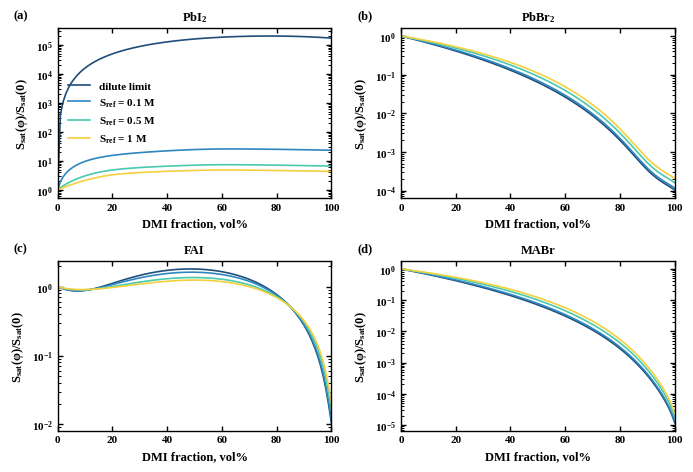

Rasm S3: suyultirilgan chegaraga nisbatan eng katta farq (log10 birlikda)


,prekursor,S_ref,max_dlog10,S_toza_DMI_nisbiy,S_toza_DMI_suyultirilgan
0,PbI2,0.1,3.907,23.404,171610.052
1,PbI2,0.5,4.454,6.658,171610.052
2,PbI2,1.0,4.638,4.353,171610.052
3,PbBr2,0.1,0.050,0.000,0.000
4,PbBr2,0.5,0.188,0.000,0.000
5,PbBr2,1.0,0.299,0.000,0.000
6,FAI,0.1,0.049,0.012,0.010
7,FAI,0.5,0.184,0.016,0.010
8,FAI,1.0,0.292,0.021,0.010
9,MABr,0.1,0.050,0.000,0.000


In [18]:
# Rasm S3: nisbiy eruvchanlik S_sat(φ)/S_sat(0) ning S_ref ga bog'liqligi (R1-2)
# Asosiy rasmlar (Rasm 3, 4) kalibrlanmagan holda S_ref = 1e-6 M — suyultirilgan chegarada hisoblangan;
# bu chegarada massa balansi ahamiyatsiz va S_ref nisbatda aniq qisqaradi.
PHI_S3 = np.linspace(0, 1, 101)
pres = [p for p in SAT]
rowsS3 = {}
if pres:
    nc = min(2, len(pres)); nr = int(np.ceil(len(pres) / nc))
    fig, axs = plt.subplots(nr, nc, figsize=(W2, 2.4 * nr), squeeze=False)
    for i, pre in enumerate(pres):
        ax = axs.flat[i]
        lim = min(C_2ME, C_DMI) / N_SITES[pre]
        for j, sref in enumerate([1e-6] + S_REF_TEST):
            if sref >= 0.98 * lim:
                continue
            S = np.array([saturation(p, BETA[pre], sref)[0] for p in PHI_S3])
            S = S / S[0]
            rowsS3[(pre, sref)] = S
            lab = "dilute limit" if sref < 1e-3 else f"$S_{{ref}}$ = {sref:g} M"
            ax.plot(100 * PHI_S3, S, color=COLORS[j % len(COLORS)], lw=1.2, label=lab)
        ax.set_yscale("log"); ax.set_xlim(0, 100)
        ax.set_xlabel("DMI fraction, vol%"); ax.set_ylabel(r"$S_{sat}(\varphi)/S_{sat}(0)$")
        ax.set_title(PRE_TEX[pre]); panel_label(ax, i)
        if i == 0:
            ax.legend(loc="best")
    for ax in axs.flat[len(pres):]:
        ax.axis("off")
    fig.tight_layout(); save(fig, "figS3_Sref"); plt.show()
    out = pd.DataFrame({f"{p}|{s:g}": v for (p, s), v in rowsS3.items()}, index=np.round(100 * PHI_S3, 1))
    out.rename_axis("phi_vol%").to_csv(f"{TABDIR}/figS3_Sref.csv")
    summ = []
    for pre in pres:
        base = rowsS3[(pre, 1e-6)]
        for s in S_REF_TEST:
            if (pre, s) in rowsS3:
                r = np.log10(rowsS3[(pre, s)] / base)
                summ.append(dict(prekursor=pre, S_ref=s, max_dlog10=np.abs(r).max(),
                                 S_toza_DMI_nisbiy=rowsS3[(pre, s)][-1], S_toza_DMI_suyultirilgan=base[-1]))
    print("Rasm S3: suyultirilgan chegaraga nisbatan eng katta farq (log10 birlikda)")
    display(pd.DataFrame(summ).round(3))

## 5b. Hisoblangan IR siljishlari (R2-3)
r²SCAN-3c/SMD(2-ME) chastotalari (`*_s4_r2freq.out` / `.hess`) dan DMI ning C=O va 2-ME ning O–H cho'zilish tebranishlari aniqlanadi
(modaning siljish energiyasi asosan shu atomlarda to'plangan bo'lsa) va erkin erituvchiga nisbatan siljish hisoblanadi.
FTIR asbobining aniqligi `FTIR_RES` da beriladi.

In [19]:
FTIR_RES = 4.0      # cm-1, FTIR spektrometr aniqligi (kerak bo'lsa o'zgartiring)
BANDS = {           # tebranish: (oyna, cm-1; atomlar to'plami)
    "C=O (DMI)": ((1500, 1800), "CO"),
    "O–H (2-ME)": ((2500, 3800), "OH"),
}
FRAC_MIN = 0.5      # moda siljishining shu ulushidan ko'pi atomlar to'plamida bo'lsa, moda shu tebranishga tegishli


def read_hess_modes(hess):
    L = open(hess, errors="ignore").read().split("\n")
    i = next(k for k, l in enumerate(L) if l.strip() == "$vibrational_frequencies")
    n = int(L[i + 1]); freqs = [float(L[i + 2 + k].split()[1]) for k in range(n)]
    i = next(k for k, l in enumerate(L) if l.strip() == "$normal_modes")
    nr, nc = map(int, L[i + 1].split())
    M = np.zeros((nr, nc)); k = i + 2
    while k < len(L):
        s = L[k].split()
        if not s or s[0].startswith("$"):
            break
        if all(re.fullmatch(r"\d+", t) for t in s):
            cols = list(map(int, s)); k += 1
            for r in range(nr):
                M[r, cols] = list(map(float, L[k + r].split()[1:]))
            k += nr
        else:
            k += 1
    return np.array(freqs), M


def read_ir_int(out):
    txt = open(out, errors="ignore").read()
    j = txt.rfind("IR SPECTRUM")
    I = {}
    if j < 0:
        return I
    for line in txt[j:].splitlines()[1:]:
        m = re.match(r"\s*(\d+):\s+(-?\d+\.\d+)\s+(\S+)\s+(\S+)", line)
        if m:
            I[int(m.group(1))] = float(m.group(4))
        elif I and line.strip() and not line.startswith(" "):
            break
    return I


def atom_sets(sym, X):
    D = np.linalg.norm(X[:, None] - X[None], axis=2)
    CO, OH = set(), set()
    for o in [i for i, s in enumerate(sym) if s == "O"]:
        nb = [j for j in range(len(sym)) if j != o and D[o, j] < 1.25 and sym[j] in ("C", "H")]
        hs = [j for j in range(len(sym)) if sym[j] == "H" and D[o, j] < 1.15]
        cs = [j for j in range(len(sym)) if sym[j] == "C" and D[o, j] < 1.30]
        if cs and not hs and len([j for j in range(len(sym)) if sym[j] == "C" and D[o, j] < 1.6]) == 1:
            CO |= {o, cs[0]}                     # karbonil O=C (bitta C qo'shni, qisqa bog')
        for h in hs:
            OH |= {o, h}
    return {"CO": CO, "OH": OH}


def ir_bands(path):
    out = s4_file(path)
    if not out:
        return None
    hess = out[:-4] + ".hess"; xyzf = out[:-4] + ".xyz"
    if not (os.path.exists(hess) and os.path.exists(xyzf)):
        return None
    at = [l.split() for l in open(xyzf).read().split("\n")[2:] if l.strip()]
    sym = [a[0] for a in at]; X = np.array([[float(v) for v in a[1:4]] for a in at])
    freqs, M = read_hess_modes(hess)
    I = read_ir_int(out)
    sets = atom_sets(sym, X)
    res = {}
    for band, ((lo, hi), key) in BANDS.items():
        idx = sorted(sets[key])
        if not idx:
            continue
        sel = []
        for k, nu in enumerate(freqs):
            if lo <= nu <= hi:
                v = M[:, k].reshape(-1, 3)
                tot = (v ** 2).sum()
                if tot > 0 and (v[idx] ** 2).sum() / tot >= FRAC_MIN:
                    sel.append((nu, I.get(k, 0.0)))
        if sel:
            nu = np.array([s[0] for s in sel]); w = np.array([s[1] for s in sel])
            res[band] = dict(nu_mean=float((nu * w).sum() / w.sum()) if w.sum() > 0 else float(nu.mean()),
                             nu_min=float(nu.min()), nu_max=float(nu.max()), n=len(nu), I_max=float(w.max()))
    return res


FREE_IR = {"C=O (DMI)": ir_bands(os.path.join(ROOT, "DMI")), "O–H (2-ME)": ir_bands(os.path.join(ROOT, "2ME"))}
FREE_IR = {b: (v or {}).get(b) for b, v in FREE_IR.items()}
rows_ir = []
for pre in data:
    for lab, p in data[pre].items():
        r = ir_bands(p)
        if not r:
            continue
        for band, v in r.items():
            f0 = FREE_IR.get(band)
            rows_ir.append(dict(prekursor=pre, label=lab, b=b_of(lab), tebranish=band, n_moda=v["n"],
                                nu=v["nu_mean"], nu_min=v["nu_min"], nu_max=v["nu_max"],
                                dnu=(v["nu_mean"] - f0["nu_mean"]) if f0 else np.nan, I_max_km_mol=v["I_max"]))
IR = pd.DataFrame(rows_ir)
if len(IR):
    IR.to_csv(f"{TABDIR}/ir_bands.csv", index=False)
    print("Erkin erituvchilar:", {b: (round(v["nu_mean"], 1) if v else None) for b, v in FREE_IR.items()})
    print("Jadval S4. Hisoblangan IR chiziqlari va erkin erituvchiga nisbatan siljish Δν, cm-1 (intensivlik bo'yicha o'rtacha)")
    display(IR.round(1))
    for band, g in IR.groupby("tebranish"):
        print(f"{band}: Δν = {g.dnu.min():+.1f} … {g.dnu.max():+.1f} cm-1  (FTIR aniqligi {FTIR_RES:g} cm-1; "
              f"|Δν| > aniqlik bo'lgan holatlar: {(g.dnu.abs() > FTIR_RES).sum()}/{len(g)})")
else:
    print("IR: s4 chastota fayllari (.out, .hess, .xyz) topilmadi")

Erkin erituvchilar: {'C=O (DMI)': 1687.2, 'O–H (2-ME)': 3791.3}
Jadval S4. Hisoblangan IR chiziqlari va erkin erituvchiga nisbatan siljish Δν, cm-1 (intensivlik bo'yicha o'rtacha)


,prekursor,label,b,tebranish,n_moda,nu,nu_min,nu_max,dnu,I_max_km_mol
0,PbI2,b0,0,O–H (2-ME),4,3672.0,3619.5,3777.0,-119.2,504.4
1,PbI2,b2_cis,2,O–H (2-ME),2,3577.2,3550.9,3716.8,-214.1,793.5
2,PbI2,b4,4,C=O (DMI),1,1681.7,1681.7,1681.7,-5.5,898.7
3,PbBr2,b0,0,O–H (2-ME),4,3383.7,3282.7,3477.5,-407.6,1503.8
4,PbBr2,b1,1,O–H (2-ME),3,3636.9,3599.0,3772.4,-154.4,569.4
5,PbBr2,b2_cis,2,O–H (2-ME),2,3381.5,3349.3,3420.0,-409.7,1443.9
6,PbBr2,b4,4,C=O (DMI),2,1673.9,1665.7,1681.6,-13.2,913.6
7,FAI,b0_c0a0,0,O–H (2-ME),4,3563.6,3445.0,3774.0,-227.7,942.0
8,FAI,b2_c2a0,2,O–H (2-ME),2,3556.2,3526.4,3592.2,-235.0,1094.2
9,FAI,b4_c2a2,4,C=O (DMI),2,1684.6,1683.8,1685.3,-2.6,1019.8


C=O (DMI): Δν = -13.2 … -2.6 cm-1  (FTIR aniqligi 4 cm-1; |Δν| > aniqlik bo'lgan holatlar: 3/4)
O–H (2-ME): Δν = -417.4 … -119.2 cm-1  (FTIR aniqligi 4 cm-1; |Δν| > aniqlik bo'lgan holatlar: 9/9)


## 6. Yakuniy sonlar — qo'lyozma va javob xati uchun
Matnda (docx va Response to Reviewers) ishlatiladigan barcha sonlar shu yerda bir joyda chiqadi va `tables/summary_numbers.txt` ga yoziladi.

In [20]:
_SUM = []


def say(line=""):
    print(line)
    _SUM.append(line)


def rng(vals, fmt="{:+.1f}"):
    vals = [v for v in vals if np.isfinite(v)]
    if not vals:
        return "—"
    lo, hi = min(vals), max(vals)
    return fmt.format(lo) if abs(hi - lo) < 0.05 else f"{fmt.format(lo)} … {fmt.format(hi)}"


say("=" * 78)
say("A. LIGAND ALMASHINISH ENERGETIKASI (3)-(4), kJ/mol — qo'lyozma sxemasi")
say("=" * 78)
for pre, df in EX.items():
    eff = dG_eff(df)
    say(f"{pre:6s} Boltsman-effektiv ΔG_b: " + ", ".join(f"b={b}: {v:+.1f}" for b, v in eff.items())
        + (f"   ΔG_n/n = {eff[N_SITES[pre]] / N_SITES[pre]:+.1f}" if N_SITES[pre] in eff else ""))
    if pre in ("PbI2", "PbBr2") and {"b2_cis", "b2_trans"} <= set(df.label):
        d = df.set_index("label").dG_kJ
        say(f"       b=2: cis − trans = {d['b2_cis'] - d['b2_trans']:+.1f} (manfiy -> cis barqarorroq)")
    if pre in ("FAI", "MABr"):
        d = df.set_index("label").dG_kJ
        offs = []
        for b in (1, 2):
            a0 = [l for l in d.index if l.startswith(f"b{b}_") and l.endswith("a0")]
            if a0:
                offs += [d[l] - d[a0[0]] for l in d.index if l.startswith(f"b{b}_") and not l.endswith("a0")]
        say(f"       b≤2: anion o'rnidagi DMI (a≥1) izomerlari a=0 dan yuqori: {rng(offs)}")
        b3 = {l: d[l] for l in d.index if l.startswith("b3_")}
        if b3:
            best = min(b3, key=b3.get)
            say(f"       b=3: eng barqaror {best} ({b3[best]:+.1f}); boshqasidan "
                f"{max(b3.values()) - min(b3.values()):.1f} past")

say()
say("=" * 78)
say("B. ERUVCHANLIK S_sat(φ)/S_sat(0) — suyultirilgan chegara (Rasm 3)")
say("=" * 78)
PH_SHOW = [5, 10, 20, 40, 50, 60, 80, 100]
for pre, s in SAT.items():
    S = s["S"]
    say(f"{pre:6s} " + "  ".join(f"{p}%: {S[np.abs(100 * PHI - p).argmin()]:.3g}" for p in PH_SHOW)
        + f"   max: {S.max():.3g} (φ = {100 * PHI[S.argmax()]:.0f}%)")
if rowsS3:
    say("Real konsentratsiyalarda (Rasm S3):")
    for pre in SAT:
        for p in (10, 50, 100):
            i = np.abs(100 * PHI_S3 - p).argmin()
            v = [rowsS3[(pre, s)][i] for s in S_REF_TEST if (pre, s) in rowsS3]
            if v:
                say(f"   {pre:6s} φ = {p:3d}%: S_ref = {S_REF_TEST[0]:g}–{S_REF_TEST[-1]:g} M da {rng(v, '{:.3g}')}"
                    f"  (suyultirilgan: {rowsS3[(pre, 1e-6)][i]:.3g})")
        base = rowsS3[(pre, 1e-6)]
        dl = [np.abs(np.log10(rowsS3[(pre, s)] / base)).max() for s in S_REF_TEST if (pre, s) in rowsS3]
        say(f"   {pre:6s} suyultirilgan chegaradan max farq: {max(dl):.2f} log10 birlik")

say()
say("=" * 78)
say("C. ASOSIY KOMPLEKS TURLARI (Rasm 4): har bir φ oralig'ida eng katta c_b/S_sat")
say("=" * 78)
for pre, s in SAT.items():
    frac = s["C"] / s["C"].sum(axis=1, keepdims=True)
    dom = frac.argmax(axis=1)
    n = N_SITES[pre]
    segs, start = [], 0
    for i in range(1, len(PHI) + 1):
        if i == len(PHI) or dom[i] != dom[start]:
            segs.append(f"{100 * PHI[start]:.0f}–{100 * PHI[i - 1]:.0f}%: (2ME){n - dom[start]}(DMI){dom[start]}")
            start = i
    say(f"{pre:6s} " + ";  ".join(segs))

if "TS1" in globals() and len(TS1):
    say()
    say("=" * 78)
    say("D. TERMOKIMYO DARAJASI (Jadval S1), kJ/mol")
    say("=" * 78)
    for pre, g in TS1.groupby("prekursor", sort=False):
        say(f"{pre:6s} B − A: {rng(g.B_minus_A)}   (geometriya {rng(g.geometriya)}, termokimyo {rng(g.termokimyo)})")
    nonfai = TS1[(TS1.prekursor != "FAI") & ~((TS1.prekursor == "PbBr2") & (TS1.b == 1))]
    say(f"PbI2, PbBr2 (b=2,4), MABr: |B − A| = {nonfai.B_minus_A.abs().min():.1f}–{nonfai.B_minus_A.abs().max():.1f}")
    if "imag_tuzatma" in TS1:
        say(f"Mavhum modalarni |ν| deb olish: max |tuzatma| = {TS1.imag_tuzatma.abs().max():.1f}; "
            f"FAI dan tashqari max = {TS1[TS1.prekursor != 'FAI'].imag_tuzatma.abs().max():.1f}")
        for _, r in TS1[TS1.n_imag_s4 > 0].iterrows():
            say(f"   {r.prekursor} {r.label}: ν = {r.imag_nu} cm-1, tuzatma {r.imag_tuzatma:+.1f}")
    say(f"qRRHO (Jadval S2): ω0 = 50–150 max = {TS2[['qRRHO_50', 'qRRHO_150']].abs().values.max():.1f};"
        f"  RRHO max = {TS2.RRHO.abs().max():.1f}")

if "TS3" in globals() and len(TS3):
    say()
    say("=" * 78)
    say("E. SEZGIRLIK TESTLARI (Jadval S3), har bir DMI uchun max |o'zgarish|, kJ/mol")
    say("=" * 78)
    per = TS3[["CPCM_minus_SMD", "epsDMI_minus_eps2ME", "wB97MV_minus_r2SCAN"]].div(TS3.b, axis=0).abs()
    for col, nm in [("epsDMI_minus_eps2ME", "Kontinuum tarkibi (ε 2-ME -> DMI)"),
                    ("wB97MV_minus_r2SCAN", "ωB97M-V/def2-TZVP vs r2SCAN-3c"), ("CPCM_minus_SMD", "CPCM vs SMD")]:
        i = per[col].idxmax()
        say(f"{nm:36s} max {per[col].max():.1f}  (median {per[col].median():.1f}; eng katta: "
            f"{TS3.loc[i, 'prekursor']} {TS3.loc[i, 'label']})")
    for col, nm in [("CPCM_minus_SMD", "CPCM"), ("wB97MV_minus_r2SCAN", "ωB97M-V")]:
        flip = TS3[np.sign(TS3.dE_SMD) != np.sign(TS3.dE_SMD + TS3[col].fillna(0))]
        say(f"{nm}: ΔE_b ishorasi o'zgargan holatlar: {len(flip)}" + (f" {list(flip.label)}" if len(flip) else ""))

if "IR" in globals() and len(IR):
    say()
    say("=" * 78)
    say(f"F. HISOBLANGAN IR SILJISHLARI (Jadval S4), cm-1; FTIR aniqligi {FTIR_RES:g}")
    say("=" * 78)
    say("Erkin erituvchi: " + ", ".join(f"{b} {v['nu_mean']:.0f}" for b, v in FREE_IR.items() if v))
    for band, g in IR.groupby("tebranish"):
        say(f"{band}: Δν = {g.dnu.min():+.1f} … {g.dnu.max():+.1f}; |Δν| > {FTIR_RES:g}: {(g.dnu.abs() > FTIR_RES).sum()}/{len(g)}")

with open(f"{TABDIR}/summary_numbers.txt", "w", encoding="utf8") as fh:
    fh.write("\n".join(_SUM) + "\n")
print(f"\nYozildi: {TABDIR}/summary_numbers.txt")

A. LIGAND ALMASHINISH ENERGETIKASI (3)-(4), kJ/mol — qo'lyozma sxemasi
PbI2   Boltsman-effektiv ΔG_b: b=0: -0.0, b=1: -22.2, b=2: -33.8, b=3: -34.0, b=4: -33.8   ΔG_n/n = -8.4
       b=2: cis − trans = -11.9 (manfiy -> cis barqarorroq)
PbBr2  Boltsman-effektiv ΔG_b: b=0: -0.0, b=1: +36.4, b=2: +13.9, b=3: +17.2, b=4: +19.6   ΔG_n/n = +4.9
       b=2: cis − trans = -12.2 (manfiy -> cis barqarorroq)
FAI    Boltsman-effektiv ΔG_b: b=0: -0.0, b=1: +6.9, b=2: -9.7, b=3: +0.4, b=4: +8.2   ΔG_n/n = +2.0
       b≤2: anion o'rnidagi DMI (a≥1) izomerlari a=0 dan yuqori: +9.5 … +14.8
       b=3: eng barqaror b3_c1a2 (+0.5); boshqasidan 7.2 past
MABr   Boltsman-effektiv ΔG_b: b=0: -0.0, b=1: +6.3, b=2: +9.1, b=3: +17.0, b=4: +25.0   ΔG_n/n = +6.3
       b≤2: anion o'rnidagi DMI (a≥1) izomerlari a=0 dan yuqori: +2.1 … +13.5
       b=3: eng barqaror b3_c2a1 (+17.1); boshqasidan 8.7 past

B. ERUVCHANLIK S_sat(φ)/S_sat(0) — suyultirilgan chegara (Rasm 3)
PbI2   5%: 4.92e+03  10%: 1.59e+04  20%: 4.92e+

## 7. Natijalarni yig'ish
Barcha rasmlar va jadvallar bitta `results.zip` arxivga yig'iladi (shu faylni yuborish kifoya).

In [21]:
import zipfile, datetime
ZIP = os.path.join(NBDIR, "results.zip")
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for d in (FIGDIR, TABDIR):
        for f in sorted(glob.glob(os.path.join(d, "*"))):
            z.write(f, os.path.join(os.path.basename(d), os.path.basename(f)))
print(f"{ZIP}  ({os.path.getsize(ZIP) / 1e6:.1f} MB, {datetime.datetime.now():%Y-%m-%d %H:%M})")

/media/doston/72f1eff3-bf18-4476-8539-c8566520c822/FACsPbI3_VASP/FACsPbI3/ORCA/2ME-DMI/results.zip  (4.0 MB, 2026-11-03 08:04)
